# Chapter 8: Modern Convolutional Networks

* Rather than trianing end-to-end (pixel to classification) systems, classical CV piplines looked more like
    1. Obtain interesting dataset (which was small and expensive, especially compared to today)
    1. Preprocess dataset with hand-crafted features on knowledge of optics, geometry, other analytics tools, and lucky discoveries by grad students
    1. Feed data through standard set of feature extractors such as SIFT (scale-invariant feature transform), SURF (speeded up robust features), or any number of hand-tuned pipelines. 
    1. Dump resultant representations into favorite classifier, say a linear model or kernel method and train said classifier

In [1]:
import torch
from torch import nn
from d2l import torch as d2l

# 8.1 Deep Convolutional Neural Networks (AlexNet)

### 8.1.1 Representation Learning

* Some researchers at the time believed (correctly), features should be learned through a learning algorithm, rather than manually engineered
* In lowest layers of network, model learned feature extractors that resembled some traditional filters. 
* Higher layers in network might build upon these representations to represent/encode larger structures like eyes, nosews, grass, etc. Ultimately, final hidden state should learn a compact representation of the image that summarizes its contents such that the data belonging to different categories can easily be separated
* Main difference between Alexnet and LeNet is availability of compute and data. Architecturally, they are very similar 
* ImageNet: 
    * Google Image Search to prefilter candidate sets for each category (where categories come from WordNet)
    * Amazon Mechanical Turk used to crowdsource pipeline to confirm each image belonging to each category
    * $224 \times 224$ pixels (w.r.t $32\times 32$) of the larger datasets of the time
* Largest vision datasets such as LAION-5B have billions of images with additional metadata
* GPUs have many more, weaker cores which allow significant parallelazability

### 8.1.2 AlexNet
* Version provided in textbook is slightly streamlined version with design quirks removed (were needed previously to make them fit onto 2 small GPUs)
* Consists of 5 Convolutional layesr, 2 fully connected layers, and 1 fully connected output layer
* AlexNet also used ReLU instead of sigmoid activation function
* Since images of ImageNet were much larger than MNIST, needed larger initial filters to pick up more visual detail
* All these layers needed 1GB in model parameters
* Due to limited memory of GPUs of the time, used dual data stream where each of the 2 GPUs could be responsible for only storing half of the model
* Sigmoids are sensitive since if parameters are not initialized properly, the activations would be close to 0 or 1, where their gradients are close to 0. This would prevent proper training This is unlike ReLUs which are 0 or 1. 
* LeNet only used weight decay, but AlexNet also used dropout and image augmentation (flipping, clipping, color change) to generate more data and enable the model to learn more robust representations. The larger "dataset" also helps reduce overfitting

In [6]:
class AlexNet(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=96, kernel_size=11, stride=4, padding=1),
            nn.ReLU(), nn.MaxPool2d(kernel_size=3, stride=2),
            nn.LazyConv2d(out_channels=256, kernel_size=5, padding=2), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.LazyConv2d(out_channels=384, kernel_size=3, padding=1), nn.ReLU(),
            nn.LazyConv2d(out_channels=384, kernel_size=3, padding=1), nn.ReLU(),
            nn.LazyConv2d(256, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2), nn.Flatten(),
            nn.LazyLinear(4096), nn.ReLU(), nn.Dropout(p=0.5),
            nn.LazyLinear(4096), nn.ReLU(),nn.Dropout(p=0.5),
            nn.LazyLinear(num_classes))
        self.net.apply(d2l.init_cnn)

AlexNet().layer_summary((1, 1, 224, 224))

Conv2d output shape:	 torch.Size([1, 96, 54, 54])
ReLU output shape:	 torch.Size([1, 96, 54, 54])
MaxPool2d output shape:	 torch.Size([1, 96, 26, 26])
Conv2d output shape:	 torch.Size([1, 256, 26, 26])
ReLU output shape:	 torch.Size([1, 256, 26, 26])
MaxPool2d output shape:	 torch.Size([1, 256, 12, 12])
Conv2d output shape:	 torch.Size([1, 384, 12, 12])
ReLU output shape:	 torch.Size([1, 384, 12, 12])
Conv2d output shape:	 torch.Size([1, 384, 12, 12])
ReLU output shape:	 torch.Size([1, 384, 12, 12])
Conv2d output shape:	 torch.Size([1, 256, 12, 12])
ReLU output shape:	 torch.Size([1, 256, 12, 12])
MaxPool2d output shape:	 torch.Size([1, 256, 5, 5])
Flatten output shape:	 torch.Size([1, 6400])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1,

### 8.1.3 Training

* Will be using FashionMNIST to train instead of ImageNet since even using modern powerful GPUs, that would still take a while
* Upsample Fashioin-MNIST to $224 \times 224$ to make dimensions work
    * Note, typically this is undesirable as it adds computational complexity without injecting additional information
* Note, we are using a much smaller learning rate (0.01) w.r.t. LeNet (0.1)
* Note, runnnning the code below made Dedicated GPU Memory take up to 11.4GB (w.r.t. 8.2 at batch size of 2048 on earlier LeNet) and ~95% on GPU (Compute saturated IG)

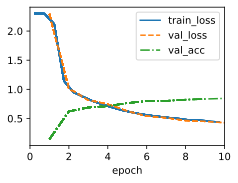

In [3]:
model = AlexNet(lr=0.01)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(model, data)

In [7]:
# Copied over from Chapter 7 notebook
def evaluate_accuracy(model, data):
    model.eval()
    device = next(model.parameters()).device

    correct, total = 0, 0

    with torch.no_grad():
        for X, y in data.get_dataloader(train=False):
            X, y = X.to(device), y.to(device)
            y_hat = model(X)
            preds = y_hat.argmax(axis=1)

            correct += (preds == y).sum().item()
            total += y.numel()

    return correct / total

### 8.1.4 Discussion

Data + Compute + Deep Learning Frameworks allowed deep learning to become more prominent

### 8.1.5 Exercises
1. Following up on the discussion above, analyze the computational properties of AlexNet.
    1. Compute the memory footprint for convolutions and fully connected layers, respectively. Which one dominates?
    1. Calculate the computational cost for the convolutions and the fully connected layers.
    1. How does the memory (read and write bandwidth, latency, size) affect computation? Is there any difference in its effects for training and inference?
1. You are a chip designer and need to trade off computation and memory bandwidth. For example, a faster chip requires more power and possibly a larger chip area. More memory bandwidth requires more pins and control logic, thus also more area. How do you optimize?
1. Why do engineers no longer report performance benchmarks on AlexNet?
1. Try increasing the number of epochs when training AlexNet. Compared with LeNet, how do the results differ? Why?
1. AlexNet may be too complex for the Fashion-MNIST dataset, in particular due to the low resolution of the initial images.
    1. Try simplifying the model to make the training faster, while ensuring that the accuracy does not drop significantly.
    1. Design a better model that works directly on $28 \times 28$ images.
1. Modify the batch size, and observe the changes in throughput (images/s), accuracy, and GPU memory.
1. Apply dropout and ReLU to LeNet-5. Does it improve? Can you improve things further by preprocessing to take advantage of the invariances inherent in the images?
1. Can you make AlexNet overfit? Which feature do you need to remove or change to break training?

Exercise #1

NOTE: Halfway through, realized I forgot to account for stride and padding, but will keep as is since idea is basically the same anyway. myb

Will assume it is talking about weights of model & forward pass (so not training, and in backwards pass). Note, using the AlexNet here so single channel
* 1 Convlutional Layer Memory
    * $c_o c_i k_h k_w + c_o  $
* 1 Fully Connected Layer Memory
    * $n_{in} n_{out} + n_{out}$

Convolution Layers Memory Contributions
* $96 \times 11 \times 11 + 96 = 11712$
* $96 \times 256 \times 5 \times 5 + 256 = 614,656$
* $256 \times 384 \times 3 \times 3 + 384 = 885,120$
* $384 \times 384 \times 3 \times 3 + 384 = 1,327,288$
* $384 \times 256 \times 3 \times 3 + 256= 884,992$
* Total = $3,723,768$ parameters

FC Layers Memory Contributions
* $6400 \times 4096 + 4096 = 26,218,496$
* $4096 \times 4096 + 4096 = 16,781,312$
* $4096 \times 10 + 10 = 40,970$
* Total = $43,040,778$ parameters

Aggregate Memory: 
* PyTorch defaults to single-precision (FP32) which as 4 bytes per parameter, so works out to $\approx 187$ MB for just storing the weights of the entire model

Computational Cost
* Convolutional Layer: $2 k_w k_h w_{out} h_{out} c_o c_{in}$ for both multiplications and additions. Additions would have 1 less per filter position, buit add it back for bias addition. 
* FC Layer: $2 n_{in} n_{out} $. Same thought process as convolutional layer.

Convolutional Layer Compute Contributions: 
* $ 2 \times 11 \times 11 \times 54 \times 54 \times 96 = 67.7$ Million
* $ 2 \times 5 \times 5 \times 26 \times 26 \times 256 \times 96 = 831$ Million
* $ 2 \times 3 \times 3 \times 12 \times 12 \times 384 \times 256 = 254.8$ Million
* $ 2 \times 3 \times 3 \times 12 \times 12 \times 384 \times 384 = 283$ Million
* $ 2 \times 3 \times 3 \times 12 \times 12 \times 384 \times 256 = 254.8$ Million
* Total: $\approx 1.7$ Billion FLOPS

FC Layer Compute Contribtions: 
* $ 2\times 6400 \times 4096 = 52.4$ Million
* $ 2\times 4096 \times 4096 = 33.6$ Million
* $ 2\times 4096 \times 10   = 41$ Thousand
* Total: $\approx 86$ Million FLOPS

Read/Write Bandwidth would affect how fast data can be moved in and out of the GPU. Importance/necessity would be related to how fast the calculations themselves are performed, which also depends on how much GPU memory there would be. Memory would determine how much stuff can be held for calculations within a single iteration such as batch size and model parameters. Training would be more intensive on both memory and compute, due to the need store gradients along with the parameters themselves, and to calculate both the forward and backwards passes. Training would also be done in batches, rather than mostly likely single-instance inputs you would see in inference. 


Exercise #2

Optimization would depend on purpose of chip, weather it is aimed for training or inferece, along with possibly if you know what model will be run on it beforehand, you can balance serial and parallel computation units. 

Exercise #3

My guess would be that AlexNet is small in terms of memory/compute it demands compared to that provided by modern computing systems, along with more complex, expressive architectures that have come out since then. 

Exercise #4

Running for 20 epochs compared to the previous 10 resulted in about 3% point improvement in validation accuracy. Note training and validation loss stayed pretty similar, without seeing any blatant divergence/numerical instability. More epochs allow the model to iterate more, which is appropriate when there are no signs of overfitting to training data. 

Final validation accuracy: 87.35%


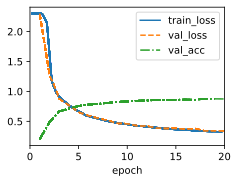

In [7]:
model_20epochs = AlexNet(lr=0.01)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
trainer = d2l.Trainer(max_epochs=20, num_gpus=1)
trainer.fit(model_20epochs, data)

val_acc_20 = evaluate_accuracy(model_20epochs, data)
print(f"Final validation accuracy: {100 * val_acc_20:.2f}%")

Exercise #5

Simplified AlexNet for FashionMnist Dataset
* No upscaling resolution
* Smaller filters, and also less convlutional layers and output channels
* Smaller FC Layers dimension, with an additional layer
* Reduced dropout probability in each FC layer to 0.3
* Got a higher validation accuracy of 91.40%

In [10]:
class FashionMNISTAlexNet(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=32, kernel_size=5, stride=1, padding=2), nn.ReLU(), 
            nn.MaxPool2d(kernel_size=2, stride=1),
            nn.LazyConv2d(out_channels=64, kernel_size=5, stride=1, padding=2), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(out_channels=64, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            nn.Flatten(),
            nn.LazyLinear(1024), nn.ReLU(), nn.Dropout(p=0.3),
            nn.LazyLinear(1024), nn.ReLU(), nn.Dropout(p=0.3),
            nn.LazyLinear(512),  nn.ReLU(), nn.Dropout(p=0.3),
            nn.LazyLinear(num_classes))
        self.net.apply(d2l.init_cnn)

FashionMNISTAlexNet().layer_summary((1, 1, 28, 28))

Conv2d output shape:	 torch.Size([1, 32, 28, 28])
ReLU output shape:	 torch.Size([1, 32, 28, 28])
MaxPool2d output shape:	 torch.Size([1, 32, 27, 27])
Conv2d output shape:	 torch.Size([1, 64, 27, 27])
ReLU output shape:	 torch.Size([1, 64, 27, 27])
MaxPool2d output shape:	 torch.Size([1, 64, 13, 13])
Conv2d output shape:	 torch.Size([1, 64, 13, 13])
ReLU output shape:	 torch.Size([1, 64, 13, 13])
Flatten output shape:	 torch.Size([1, 10816])
Linear output shape:	 torch.Size([1, 1024])
ReLU output shape:	 torch.Size([1, 1024])
Dropout output shape:	 torch.Size([1, 1024])
Linear output shape:	 torch.Size([1, 1024])
ReLU output shape:	 torch.Size([1, 1024])
Dropout output shape:	 torch.Size([1, 1024])
Linear output shape:	 torch.Size([1, 512])
ReLU output shape:	 torch.Size([1, 512])
Dropout output shape:	 torch.Size([1, 512])
Linear output shape:	 torch.Size([1, 10])


Final validation accuracy: 91.40%


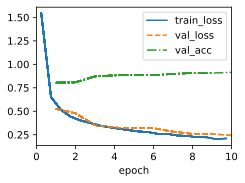

In [11]:
FashionMNISTAlexNet = FashionMNISTAlexNet()
data = d2l.FashionMNIST(batch_size=128) # No resizing model for this exercise
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(FashionMNISTAlexNet, data)

val_acc_20 = evaluate_accuracy(FashionMNISTAlexNet, data)
print(f"Final validation accuracy: {100 * val_acc_20:.2f}%")

Exercise #6

* Same model as above from Exercise #5, but just with a larger batch size
    * Batch Size of 256:  Final Validation Accuracy of 90.24%
    * Batch Size of 1024: Final Validation Accuracy of 78.53%
    * Batch Size of 2048: Final Validation Accuracy of 75.76%
* Notice how larger batch sizes seem to degrade model performance. Perhaps the smaller batch size served as a form of regularization by introducing more variation (within each batch) per iteration. The largest batch size tested (2048) had very noticable numerical instability during the training process for a lr of 0.1, even though each batch can be thought of a more representative of the entire training set. Also, a larger batch size would mean less iterations per epoch, meaning there are less opportunities for updating the parameters and "getting feedback" on them. 
* Higher batch sizes used more Dedicated GPU Memory but I forgot to record/note their relative values (I had other GPU tasks running in background so peak usage was around 14.3 GB)

In [29]:
class FashionMNISTAlexNet(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=16, kernel_size=5, stride=1, padding=2), nn.ReLU(), 
            nn.MaxPool2d(kernel_size=2, stride=1),
            nn.LazyConv2d(out_channels=32, kernel_size=5, stride=1, padding=2), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(out_channels=32, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            nn.Flatten(),
            nn.LazyLinear(512), nn.ReLU(), nn.Dropout(p=0.3),
            nn.LazyLinear(512), nn.ReLU(), nn.Dropout(p=0.3),
            nn.LazyLinear(256),  nn.ReLU(), nn.Dropout(p=0.3),
            nn.LazyLinear(num_classes))
        self.net.apply(d2l.init_cnn)

FashionMNISTAlexNet().layer_summary((1, 1, 28, 28))

Conv2d output shape:	 torch.Size([1, 16, 28, 28])
ReLU output shape:	 torch.Size([1, 16, 28, 28])
MaxPool2d output shape:	 torch.Size([1, 16, 27, 27])
Conv2d output shape:	 torch.Size([1, 32, 27, 27])
ReLU output shape:	 torch.Size([1, 32, 27, 27])
MaxPool2d output shape:	 torch.Size([1, 32, 13, 13])
Conv2d output shape:	 torch.Size([1, 32, 13, 13])
ReLU output shape:	 torch.Size([1, 32, 13, 13])
Flatten output shape:	 torch.Size([1, 5408])
Linear output shape:	 torch.Size([1, 512])
ReLU output shape:	 torch.Size([1, 512])
Dropout output shape:	 torch.Size([1, 512])
Linear output shape:	 torch.Size([1, 512])
ReLU output shape:	 torch.Size([1, 512])
Dropout output shape:	 torch.Size([1, 512])
Linear output shape:	 torch.Size([1, 256])
ReLU output shape:	 torch.Size([1, 256])
Dropout output shape:	 torch.Size([1, 256])
Linear output shape:	 torch.Size([1, 10])


Final validation accuracy: 90.24%


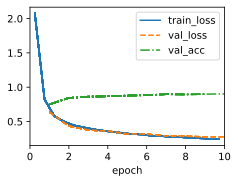

In [24]:
FashionMNISTAlexNet = FashionMNISTAlexNet()
data = d2l.FashionMNIST(batch_size=128) # No resizing model for this exercise
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(FashionMNISTAlexNet, data)

val_acc = evaluate_accuracy(FashionMNISTAlexNet, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Final validation accuracy: 78.53%


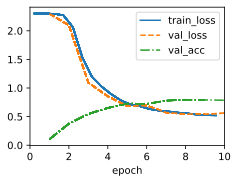

In [27]:
FashionMNISTAlexNet = FashionMNISTAlexNet()
data = d2l.FashionMNIST(batch_size=1024) # No resizing model for this exercise
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(FashionMNISTAlexNet, data)

val_acc = evaluate_accuracy(FashionMNISTAlexNet, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Exercise #7

* Original LeNet from Chapter 7 had val acc of:         73.40%
* Current version with dropout and ReLU had val acc of: 75.27%
* Slight improvement

In [37]:
class LeNetEx7(d2l.Classifier):
    """
    Copied straight from Chapter 7
    
    Also added Dropout to FC layers and swapped out Sigmoid for ReLU activations
    """
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=6, kernel_size=5, padding=2), nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(out_channels=16, kernel_size=5), nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.LazyLinear(out_features=120), nn.ReLU(), nn.Dropout(p=0.3),
            nn.LazyLinear(out_features=84), nn.ReLU(),  nn.Dropout(p=0.3),
            nn.LazyLinear(out_features=num_classes),    nn.Dropout(p=0.3)
        )
        self.net.apply(d2l.init_cnn)

model = LeNetEx7()
model.layer_summary((1, 1, 28, 28))

Conv2d output shape:	 torch.Size([1, 6, 28, 28])
Sigmoid output shape:	 torch.Size([1, 6, 28, 28])
AvgPool2d output shape:	 torch.Size([1, 6, 14, 14])
Conv2d output shape:	 torch.Size([1, 16, 10, 10])
Sigmoid output shape:	 torch.Size([1, 16, 10, 10])
AvgPool2d output shape:	 torch.Size([1, 16, 5, 5])
Flatten output shape:	 torch.Size([1, 400])
Linear output shape:	 torch.Size([1, 120])
ReLU output shape:	 torch.Size([1, 120])
Dropout output shape:	 torch.Size([1, 120])
Linear output shape:	 torch.Size([1, 84])
ReLU output shape:	 torch.Size([1, 84])
Dropout output shape:	 torch.Size([1, 84])
Linear output shape:	 torch.Size([1, 10])
Dropout output shape:	 torch.Size([1, 10])


Final validation accuracy: 75.27%


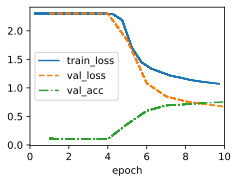

In [38]:
LeNetEx7 = LeNetEx7()
data = d2l.FashionMNIST(batch_size=128) # No resizing model for this exercise
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(LeNetEx7, data)

val_acc = evaluate_accuracy(LeNetEx7, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Transforms for preprocessing (i.e. rotations, translations, flips)

1. https://github.com/d2l-ai/d2l-en/blob/master/d2l/torch.py#L428
1. https://docs.pytorch.org/vision/0.22/transforms.html

Seems like d2l.FashionMNIST only has the resize transform, not the whole available arbitrary functionalities of data augmentation. 

Could try by using the directly the PyTorch versions, not the d2l wrapper. Should come back to this later...

Exercise #8

* Making AlexNet overfit by getting rid of dropout, and greatly increasing layer count and dimensions of FC layers
* Didn't really work seeing that training & validation losses are lockstep with each other. Probably just scale up model even more to make it overfit...

Final validation accuracy: 90.01%


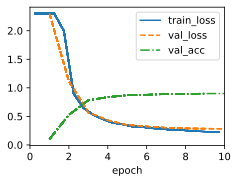

In [45]:
class AlexNetOverfit(d2l.Classifier):
    """Copied from earlier in this 8.1 Section"""
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=96, kernel_size=11, stride=4, padding=1),
            nn.ReLU(), nn.MaxPool2d(kernel_size=3, stride=2),
            nn.LazyConv2d(out_channels=256, kernel_size=5, padding=2), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.LazyConv2d(out_channels=384, kernel_size=3, padding=1), nn.ReLU(),
            nn.LazyConv2d(out_channels=384, kernel_size=3, padding=1), nn.ReLU(),
            nn.LazyConv2d(256, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2), 
            nn.Flatten(),
            nn.LazyLinear(8192), nn.ReLU(),
            nn.LazyLinear(8192), nn.ReLU(),
            nn.LazyLinear(8192), nn.ReLU(),
            nn.LazyLinear(4096), nn.ReLU(), 
            nn.LazyLinear(num_classes))
        self.net.apply(d2l.init_cnn)

# AlexNetOverfit().layer_summary((1, 1, 224, 224))
# AlexNetOverfit().layer_summary((1, 1, 28, 28))

model = AlexNetOverfit()
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224)) # No resizing model for this exercise
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(model, data)

val_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

# 8.2 Networks Using Blocks (VGG)

* Analogy of VLSI/Chip designers moving from designing transistors, to logic gates, to circuits/blocks (basically just moving up abstraction chains)
* In neural network designers, researhers moved away from thinking in terms of inidividual neurons to whole layers, to whole blocks of repeating layers
* Researchers sometimes use entire trained models to repurpose them for different but still related tasks. Such pretrained models are typically called _foundation models_

In [1]:
import torch
from torch import nn
from d2l import torch as d2l

### 8.2.1 VGG Blocks

* Basic building block of CNN is sequence of following:
    1. Convolutional layer w/ padding to maintain resolution
    1. Nonlinearity (such as ReLU)
    1. Pooling Layer (usually max pooling for invariance and spatial dimension reduction)
* Note spatial reduction of max pooling imposes a lard limit of $\log_2{d}$ convolutional layers where $d$ is the limiting dimension. For ImageNet ($224 \times 224$), this makes it impossible to hae more than 8 convolutional layers ($2^8 = 256$)
* Key Idea/Contribution of Simonyan and Zisserman (2014) was to use _multiple_ convolutoin between downsampling MaxPool layers to form a block
    * They were interested in whether deep or wide networks perform better
    * e.g. two $3\times 3$ vs one $5\times 5$ convolutional filter touches the same incoming image (at said layer/block)
    * However, takes three $3 \times 3$ filters to have roughly same paramter count as a single $5\times 5$ filter
    * Stacking $3\times 3$ filters became standard until "Convnet for 2020's"
* VGG Block Itself:
    * Sequence of $3\times 3$ convolution layers with padding of 1 (to preserve dimensionality)
    * Max Pool of $2\times 2$ at the end of block w/ stride 2 (reduce both height/width of 2, decrease # of pixels by 75%)

In [2]:
def vgg_block(num_convs, out_channels):
    layers = []
    for _ in range(num_convs):
        layers += [nn.LazyConv2d(out_channels, kernel_size=3, padding=1), nn.ReLU()]
    layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
    # Need to unpack list. nn.Sequential only takes subclasses of nn.Module 
    # subclass, which a list itself is not
    return nn.Sequential(*layers)  

vgg_block(3, 16)

Sequential(
  (0): LazyConv2d(0, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): LazyConv2d(0, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU()
  (4): LazyConv2d(0, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)

### 8.2.2 VGG Network

* Overall VGG network can be divided into layers of VGG Blocks described above, followed by FC layers (Kinda like AlexNet)
* Note - VGG describes _family_ of networks rather than a specific configuration/design
* Original VGG had 5 convolutional blocks, where first 2 had one convolutional layer each, and latter 3 had two convolutional layers each 
* First block has 64 output channels, and each block doubles that until 512 (64, 128, 256, 512, 512), and last block is 512 asw. 
* VGG-11: Namesake comes from $8$ convolutional layers ($2 \times 1 + 3 \times 2 = 8$) and $3$ FC layers

In [3]:
class VGG(d2l.Classifier):
    def __init__(self, architecture: tuple, lr=0.05, num_classes=10):
        """architecture is a tuple of tuples, where each inner tuple is (num_convs, out_channels)
        """
        super().__init__()
        self.save_hyperparameters()
        conv_blocks = []
        for (num_convs, out_channels) in architecture:
            conv_blocks.append(vgg_block(num_convs, out_channels))
        self.net = nn.Sequential(
            *conv_blocks, nn.Flatten(),
            nn.LazyLinear(4096), nn.ReLU(), nn.Dropout(p=0.5),
            nn.LazyLinear(4096), nn.ReLU(), nn.Dropout(p=0.5),
            nn.LazyLinear(num_classes)
        )
        self.net.apply(d2l.init_cnn)

# Note: Instantiating this class as "VGG" overwrite VGG as a class to a instance of the class, causing
# issues in the next cell when I try to instantiate VGG again to properly train it
VGGTest = VGG(architecture=((1, 64), (1, 128), (2, 256), (2, 512), (2, 512)))
VGGTest.layer_summary((1, 1, 224, 224))


Sequential output shape:	 torch.Size([1, 64, 112, 112])
Sequential output shape:	 torch.Size([1, 128, 56, 56])
Sequential output shape:	 torch.Size([1, 256, 28, 28])
Sequential output shape:	 torch.Size([1, 512, 14, 14])
Sequential output shape:	 torch.Size([1, 512, 7, 7])
Flatten output shape:	 torch.Size([1, 25088])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1, 10])


### 8.2.3 Training

* Will be using smaller than actual OG VGG due to computational demands. 
* Scaled down VGG should be sufficient for FashionMNIST tho
* Train and Validation in lockstep indicate little to no overfitting
* Final Validation Accuracy of: 

Q: Why do we need the "model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)" line even though: "self.net.apply(d2l.init_cnn)" is passed within __init__ of VGG class?

A: Model has lazy layers. At construction/definition, they do not know their weight shapes yet (until they see an input shape). 

https://github.com/d2l-ai/d2l-en/blob/master/d2l/torch.py#L228 

The model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn) line passes the first minibatch of data through the initialized model, and applied initialized of xavier on linear and conv layers by apply_init using the d2l.init_cnn argument

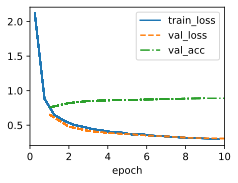

In [ ]:
model = VGG(architecture=((1, 16), (1, 32), (2, 64), (2, 128), (2, 128)), lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

In [20]:
val_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Final validation accuracy: 88.88%


### 8.2.4 Summary

* First "modern" CNN
* Helped popularize deep and narrow CNNs
* Easier to generate deeper networks, without typing out different layers manually

### 8.2.5 Exercises
1. Compared with AlexNet, VGG is much slower in terms of computation, and it also needs more GPU memory. 
    1. Compare the number of parameters needed for AlexNet and VGG.
    1. Compare the number of floating point operations used in the convolutional layers and in the fully connected layers. 
    1. How could you reduce the computational cost created by the fully connected layers?
1. When displaying the dimensions associated with the various layers of the network, we only see the information associated with eight blocks (plus some auxiliary transforms), even though the network has 11 layers. Where did the remaining three layers go?
1. Use Table 1 in the VGG paper Simonyan.Zisserman.2014 to construct other common models, such as VGG-16 or VGG-19.
1. Upsampling the resolution in Fashion-MNIST eight-fold from $28 \times 28$ to $224 \times 224$ dimensions is very wasteful. Try modifying the network architecture and resolution conversion, e.g., to 56 or to 84 dimensions for its input instead. Can you do so without reducing the accuracy of the network? Consult the VGG paper Simonyan.Zisserman.2014 for ideas on adding more nonlinearities prior to downsampling.

In [22]:
VGGTest = VGG(architecture=((1, 64), (1, 128), (2, 256), (2, 512), (2, 512)))
VGGTest.layer_summary((1, 1, 224, 224))

Sequential output shape:	 torch.Size([1, 64, 112, 112])
Sequential output shape:	 torch.Size([1, 128, 56, 56])
Sequential output shape:	 torch.Size([1, 256, 28, 28])
Sequential output shape:	 torch.Size([1, 512, 14, 14])
Sequential output shape:	 torch.Size([1, 512, 7, 7])
Flatten output shape:	 torch.Size([1, 25088])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1, 10])


Exercise #1
* Note - FashionMNIST is single channel dataset
* Parameters per NN Component
    * Linear: $ w_i \cdot w_o + w_o $
    * Conv:   $ c_o (k_w \cdot k_h \cdot c_i + 1) $
* Compute per NN Component (FLOPs)
    * Linear: $ 2\cdot w_i \cdot w_o$
    * Conv:   $ 2\cdot h \cdot w \cdot k_w \cdot k_h \cdot c_i \cdot c_o$
* Total Parameters Needed (just for model, not training):
    * AlexNet: 46.7 Million (copied from section 8.1)
    * VGG: 128.8 Million
        * Conv1: $ 64\cdot (3 \cdot 3 \cdot 1 + 1) = 640$ 
        * Conv2: $ 128 \cdot (64 \cdot 3 \cdot + 1) = 73,856$
        * Conv3: $ 256 \cdot (128 \cdot 3 \cdot 3 + 1) + 256 \cdot (256 \cdot 3 \cdot 3 + 1)= 885,248$
        * Conv4: $ 512 \cdot (512 \cdot 3 \cdot 3 + 1) + 512 \cdot (256 \cdot 3 \cdot 3 + 1) = 3,539,968$
        * Conv5: $ 2\cdot 512 \cdot (512 \cdot 3 \cdot 3 + 1) = 4,719,616$
        * Lin 1, 2, 3: $ (25,088\cdot 4,096 + 4,096) + (4,096 \cdot 4,096 + 4,096 ) + (4,096 \cdot 10 + 10 ) = 119,586,826$
        
* Total FLOPs Needed (single forward pass):
    * AlexNet: $\approx 1.8$ billion FLOPs (copied from section 8.1)
    * VGG: $\approx 15.1$ billion FLOPs
        * Conv1: $2\cdot (224 \cdot 224 \cdot 3 \cdot 3 \cdot 1 \cdot 64) = 57,802,752$
        * Conv2: $2\cdot (112 \cdot 112 \cdot 3 \cdot 3 \cdot 64 \cdot 128) = 1,849,688,064$
        * Conv3: $2\cdot (56 \cdot 56 \cdot 3 \cdot 3 \cdot 128 \cdot 256) + 2\cdot (56 \cdot 56 \cdot 3 \cdot 3 \cdot 256 \cdot 256) = 5,549,064,192$
        * Conv4: $2\cdot (28 \cdot 28 \cdot 3 \cdot 3 \cdot 256 \cdot 512) + 2\cdot (28 \cdot 28 \cdot 3 \cdot 3 \cdot 512 \cdot 512) = 5,549,064,192$
        * Conv5: $2\cdot (14 \cdot 14 \cdot 3 \cdot 3 \cdot 512 \cdot 512) + 2\cdot (14 \cdot 14 \cdot 3 \cdot 3 \cdot 512 \cdot 512) = 1,849,688,064$ 
        * Lin 1, 2, 3: $2\cdot (25,088 \cdot 4,096 + 4,096 \cdot 4,096 + 4,096 \cdot 10) = 239,157,248$
* Network-in-Network (Read ahead and going exercises on 2nd pass)
    * FC layers are memory heavy, replace with $1\times 1$ conv layers to introduce more nonlinearities to increase expressivity 


Exercise #2

* They are grouped in the 3rd, 4th, 5th convolutional layers since the layer summary will only show the blocks (of which, 3, 4, 5 are sequential blocks containing 2 convolutional layers each)

Exercise #3

* VGG-13 below
* Training time of: Takes too long. Much more compute than the simplied one for MNIST (the one with actual channel dimensions from VGG paper)

In [ ]:
VGG_13 = VGG(architecture=( (2, 64), (2, 128), (3, 256), (3, 512), (3, 512) ) )

Sequential output shape:	 torch.Size([1, 64, 112, 112])
Sequential output shape:	 torch.Size([1, 128, 56, 56])
Sequential output shape:	 torch.Size([1, 256, 28, 28])
Sequential output shape:	 torch.Size([1, 512, 14, 14])
Sequential output shape:	 torch.Size([1, 512, 7, 7])
Flatten output shape:	 torch.Size([1, 25088])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1, 10])


Exercise #4

* Modified network with no resolution upsampling
* Idea for adding nonlinearites prior to downsampling - $1\times 1$ convolutions after "standard" convolutional layers and before the MaxPool downsampling
* Note - 88.88% evaluation accuracy from earlier
* Best performance for model without downsampling is 87.36% accuracy (slight decrease), but save a lot on unnecessary compute
* Haven't added in non-linearites from $1\times 1$ 

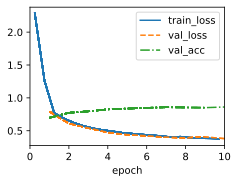

In [6]:
model = VGG(architecture=((2, 32), (3, 64)), lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(28, 28))
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

In [8]:
og_res_model = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * og_res_model:.2f}%")

Final validation accuracy: 86.04%


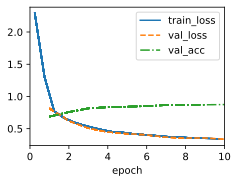

In [11]:
model = VGG(architecture=((3, 64), (5, 128)), lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(28, 28))
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

In [12]:
second_iter_model = evaluate_accuracy(model, data)
print(f"Second iteration validation accuracy: {100 * second_iter_model:.2f}%")

Second iteration validation accuracy: 87.36%


# 8.3 Network in Network (NiN)

* LeNet, AlexNet, VGG all share common architecture of extrating feature that exploit spatial structure of images via a sequence of convolutions and pooling layers and post-process the representations of the convolutions via FC layers
* Improvements of AlexNet and VGG (w.r.t. LeNet) are primarily based on how to make same network wider and deeper 

1. FC Layers at end of CNN consume a large number of parameters and memory (majority of int in fact)
1. Can't add FC layers in between convolutional blocks to increase non-linearity, as that would destroy the spatial structure
    * Technically flattening/unflattening operations on image tensor to vector and back again won't destroy spatial structure, but the FC layer's weights don't respect the spatial structure of images (locality, translation invariance)
    * What the 2013 NiN paper propsed is to use $1\times 1$ convolution to add local nonlinearites across channel activations and use global average pooling to integrate across all locations in last representation layer. NOTE, Global average pooling would not be effective without the added nonlinearites. This fact will be explored below...

In [65]:
import torch
from torch import nn
from d2l import torch as d2l

### 8.3.1 NiN Blocks

* Inputs/Outputs of Convolutional Layers look like: (example index, channel, height, width)
* Inputs/Outputs of Fully Connected Layers look like: (example, feature)
* Reference - VGG Blocks
    * Multiple $3 \times 3$ convolution layers, followed by a MaxPool
* NiN Blocks
    * Initial Convolutional Layer (any kernel dimension)
    * Some number of $1 \times 1$ convolutions (say two for now)
    * Followed by MaxPool layer. Note, at the very last block, it will end with a Global Average Pool (reduces multidimension feature map into single 1D vector )
    * Note - there is no large FC layer(s) at the end of the CNN/MaxPool/ReLU blocks

In [13]:
def nin_block(out_channels, kernel_size, strides, padding):
    """
    out_channels is the number of output channels for all conv layers in the block. 
    kernel_size, strides, and padding are only for the first conv layer. """
    return nn.Sequential(
        nn.LazyConv2d(out_channels, kernel_size, strides, padding), nn.ReLU(),
        nn.LazyConv2d(out_channels, kernel_size=1), nn.ReLU(),
        nn.LazyConv2d(out_channels, kernel_size=1), nn.ReLU()
    )

### 8.3.2 NiN Model

* Proposed shortly after AlexNet, so uses same filter sizes
* No FC layer which decreases memory use significantly, but probably will have increase in training/compute times (recall FC layer take most of memory, but conv layers take most of compute)
* Final layer is a Global Average Poolling Layer, which will return a vector of logits to be passed through a softmax operation 

In [33]:
class NiN(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nin_block(out_channels=96, kernel_size=11, strides=4, padding=0),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nin_block(out_channels=256, kernel_size=5, strides=1, padding=2),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nin_block(out_channels=384, kernel_size=3, strides=1, padding=1),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Dropout(0.5),
            nin_block(out_channels=num_classes, kernel_size=3, strides=1, padding=1),
            nn.AdaptiveAvgPool2d( (1, 1) ),
            nn.Flatten()
        )
        self.net.apply(d2l.init_cnn)

NiNTestInst = NiN()
NiNTestInst.layer_summary((1, 1, 224, 224))

Sequential output shape:	 torch.Size([1, 96, 54, 54])
MaxPool2d output shape:	 torch.Size([1, 96, 26, 26])
Sequential output shape:	 torch.Size([1, 256, 26, 26])
MaxPool2d output shape:	 torch.Size([1, 256, 12, 12])
Sequential output shape:	 torch.Size([1, 384, 12, 12])
MaxPool2d output shape:	 torch.Size([1, 384, 5, 5])
Dropout output shape:	 torch.Size([1, 384, 5, 5])
Sequential output shape:	 torch.Size([1, 10, 5, 5])
AdaptiveAvgPool2d output shape:	 torch.Size([1, 10, 1, 1])
Flatten output shape:	 torch.Size([1, 10])


### 8.3.3 Training

Train on FashionMNIST again with same optimizer/learning algo for AlexNet and VGG

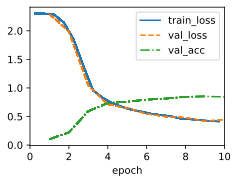

In [34]:
model = NiN(lr=0.05)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

In [35]:
val_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Final validation accuracy: 84.19%


### 8.3.4 Summary
* NiN has fewer parameters than VGG/AlexNet due to replacing FC layers with additional nonlinearities introduced through $1\times 1$ convolution layers
* Takes longer to train tho
* Supposedly did not harm accuracy

### 8.3.5 Exercises
1. Why are there two $1\times 1$ convolutional layers per NiN block? Increase their number to three. Reduce their number to one. What changes?
1. What changes if you replace the $1 \times 1$ convolutions by $3 \times 3$ convolutions? 
1. What happens if you replace the global average pooling by a fully connected layer (speed, accuracy, number of parameters)?
1. Calculate the resource usage for NiN.
    1. What is the number of parameters?
    1. What is the amount of computation?
    1. What is the amount of memory needed during training?
    1. What is the amount of memory needed during prediction?
1. What are possible problems with reducing the $384 \times 5 \times 5$ representation to a $10 \times 5 \times 5$ representation in one step?

Exercise #1 

* Model with 1 1x1 conv validation accuracy: 88.27%
* Model with 2 1x1 conv validation accuracy: 67.57%
    * Learning process is quite slow and quite unstable
* Model with 3 1x1 conv validation accuracy: 72.35%
    * Learning process is quite slow and quite unstable

In [36]:
def nin_block(out_channels, kernel_size, strides, padding, num_1_by_1_convs=2):
    """nin block where number of 1x1 convolution can be specified"""
    blocks = []
    blocks.append(nn.LazyConv2d(out_channels, kernel_size, strides, padding))
    blocks.append(nn.ReLU())
    for _ in range(num_1_by_1_convs):
        blocks.append(nn.LazyConv2d(out_channels, kernel_size=1))
        blocks.append(nn.ReLU())
    return nn.Sequential(*blocks)

In [38]:
class NiN(d2l.Classifier):
    """Added argument to nin_block to specify number of 1x1 convs in the block, 
    but left it at default of 2 for the NiN architecture"""
    def __init__(self, lr=0.1, num_classes=10, num_1_by_1_convs=2):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nin_block(out_channels=96, kernel_size=11, strides=4, padding=0, num_1_by_1_convs=num_1_by_1_convs),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nin_block(out_channels=256, kernel_size=5, strides=1, padding=2, num_1_by_1_convs=num_1_by_1_convs),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nin_block(out_channels=384, kernel_size=3, strides=1, padding=1, num_1_by_1_convs=num_1_by_1_convs),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Dropout(0.5),
            nin_block(out_channels=num_classes, kernel_size=3, strides=1, padding=1, num_1_by_1_convs=num_1_by_1_convs),
            nn.AdaptiveAvgPool2d( (1, 1) ),
            nn.Flatten()
        )
        self.net.apply(d2l.init_cnn)

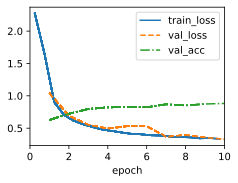

In [39]:
model1 = NiN(lr=0.05, num_1_by_1_convs=1)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model1.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model1, data)

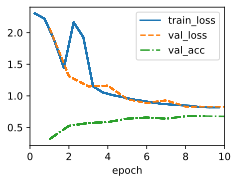

In [40]:
model2 = NiN(lr=0.05, num_1_by_1_convs=2) # Same as before/default
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model2.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model2, data)

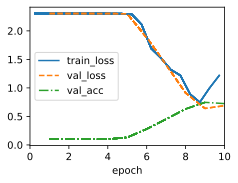

In [41]:
model3 = NiN(lr=0.05, num_1_by_1_convs=3)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model3.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model3, data)

In [42]:
model1_val_acc = evaluate_accuracy(model1, data)
model2_val_acc = evaluate_accuracy(model2, data)
model3_val_acc = evaluate_accuracy(model3, data)

print(f"Model with 1 1x1 conv validation accuracy: {100 * model1_val_acc:.2f}%")
print(f"Model with 2 1x1 conv validation accuracy: {100 * model2_val_acc:.2f}%")
print(f"Model with 3 1x1 conv validation accuracy: {100 * model3_val_acc:.2f}%")

Model with 1 1x1 conv validation accuracy: 88.27%
Model with 2 1x1 conv validation accuracy: 67.57%
Model with 3 1x1 conv validation accuracy: 72.35%


Exercise #2
* If $1\times 1$ convolutions are replaced by $3\times 3$ convolution, just end up with a variant of VGG CNN with no FC layer at the end

Exercise #3
* Comparisons are done with the baseline of the NiN presented in the textbook
* Replacing Global Average Pooling layer with FC layer would:
    * Increase number of parameters
    * Decrease both training and prediction time slightly (conv layers would still dominate)
        * Training time of 6m20s before, now is 6m13s
    * Accuracy increased to 89.25% from 75.77%

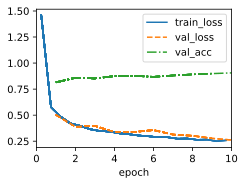

In [43]:
class NiN_ex3(d2l.Classifier):
    """Added argument to nin_block to specify number of 1x1 convs in the block, 
    but left it at default of 2 for the NiN architecture. Final 1x1 conv layer
    was dropped in favor of linear layer."""
    def __init__(self, lr=0.1, num_classes=10, num_1_by_1_convs=2):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nin_block(out_channels=96, kernel_size=11, strides=4, padding=0, num_1_by_1_convs=num_1_by_1_convs),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nin_block(out_channels=256, kernel_size=5, strides=1, padding=2, num_1_by_1_convs=num_1_by_1_convs),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nin_block(out_channels=384, kernel_size=3, strides=1, padding=1, num_1_by_1_convs=num_1_by_1_convs),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Dropout(0.5),
            nn.Flatten(), 
            nn.LazyLinear(num_classes)
        )
        self.net.apply(d2l.init_cnn)


model_ex3 = NiN_ex3(lr=0.05)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model_ex3.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model_ex3, data)

In [44]:
val_acc_ex3 = evaluate_accuracy(model_ex3, data)
print(f"Validation accuracy for NiN_ex3: {val_acc_ex3}")

Validation accuracy for NiN_ex3: 0.9061


Exercise #4
* Refer to baseline NiN given in textbook
* Not in the mood for this kind of exercise again. Most likely will rseult in noticably less memory than VGG or previous CNNs, but take more compute (since that is the tradeoff relationship between linear and conv layers, and that would be expected in an network consisting purely of conv layers)
1. Parameter Count: Decrease
1. Computation Needed: Increase
1. Memory Needed for Training: Decrease
1. Memory Needed for Prediction: Decrease

Exercise #5
* Excessive dimension reduction/compression might cause you to lose out on a lot of the representational knowledge

# 8.4 Multi-Branch Networks (GoogLeNet)
* Possibly first CNN with clear distinction between:
    * Stem: Data Ingest (first 2-3 convolutions on the image that extract lower level features)
    * Body: Data Processing (body of convolution blocks to build representaitons)
    * Head: Prediction (downstream i.e. classification, segmentaiton, detection, tracking, etc.)
* Instead of trying to figure out what size of kernels to use (ranging from $1\times 1$ to $11 \times 11$), just use a bunch of them for a given input for a concatenated multi-branch convolution
* This version is slightly modified from original version, where it had some tricks to stability training through intermediate loss functions (in the form of multiple additinal layers), but they are no longer needed due to better training algorithims

In [47]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

### 8.4.1 Inception Blocks
* Middle two branches add $1 \times 1$ convolutions before the actual filters to reduce the number of channels (input Image is porbably 3, but for "middle" blocks, incoming channel count could be rather high) to reduce model complexity 
* Note, each branch should use appropriate padding for dimension preservation 
* At the end of the block, each branch should be concatenated along the _channel_ dimension
* Important Hyperparameter - Output Channel Count for each branch - effectively how much to weight each filter/branch
* Intuition: Each branch (corresponding to different kernel sizes) allows model/block to pick up on varying details/features at different scales of the representation 

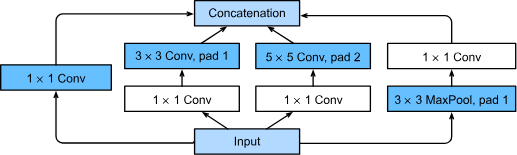

In [48]:
class Inception(nn.Module):
    """
    c1,...,c4 indicate number of output channels per branch
    """
    def __init__(self, c1, c2, c3, c4, **kwargs):
        super().__init__(**kwargs)
        # Branch 1: 1x1 conv
        self.b1 = nn.LazyConv2d(out_channels=c1, kernel_size=1)
        # Branch 2: 1x1 conv -> 3x3 conv w/ padding=1
        self.b2_1 = nn.LazyConv2d(out_channels=c2[0], kernel_size=1)
        self.b2_2 = nn.LazyConv2d(out_channels=c2[1], kernel_size=3, padding=1)
        # Branch 3: 1x1 conv -> 5x5 conv w/ padding=2
        self.b3_1 = nn.LazyConv2d(out_channels=c3[0], kernel_size=1)
        self.b3_2 = nn.LazyConv2d(out_channels=c3[1], kernel_size=5, padding=2)
        # Branch 4: 3x3 max pooling -> 1x1 conv
        self.b4_1 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
        self.b4_2 = nn.LazyConv2d(out_channels=c4, kernel_size=1)

    def forward(self, X):
        b1 = F.relu(self.b1(X))
        b2 = F.relu(self.b2_2(F.relu(self.b2_1(X))))
        b3 = F.relu(self.b3_2(F.relu(self.b3_1(X))))
        b4 = F.relu(self.b4_2(self.b4_1(X)))
        return torch.cat((b1, b2, b3, b4), dim=1) # Channel dimension

### 8.4.2 GoogLeNet Model 

* Original GoogLeNet used a stack of 9 inception blcoks arranged as below with MaxPool in between each Inception block for dimensino reduction
* Initial stem (data ingest) portion is similar to AlexNet

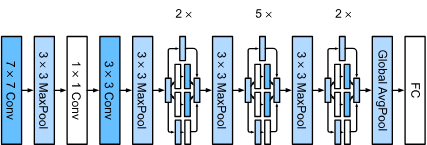

In [59]:
class GoogLeNet(d2l.Classifier):
    def __init__(self, lr=0.05, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(self.section1(),
                                 self.section2(),
                                 self.section3(),
                                 self.section4(),
                                 self.section5(),
                                nn.LazyLinear(num_classes)
                                )
        self.net.apply(d2l.init_cnn)

    def section1(self):
        b1 = nn.Sequential(
            nn.LazyConv2d(out_channels=64, kernel_size=7, stride=2, padding=3), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return b1

    def section2(self):
        b2 = nn.Sequential(
        nn.LazyConv2d(out_channels=64, kernel_size=1), nn.ReLU(),
        nn.LazyConv2d(out_channels=192, kernel_size=3, padding=1), nn.ReLU(),
        nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
        return b2

    def section3(self):
        b3 = nn.Sequential(
            Inception(64, (96, 128), (16, 32), 32),
            Inception(128, (128, 192), (32, 96), 64),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return b3
    
    def section4(self):
        b4 = nn.Sequential(
                        Inception(192, (96, 208), (16, 48), 64),
                        Inception(160, (112, 224), (24, 64), 64),
                        Inception(128, (128, 256), (24, 64), 64),
                        Inception(112, (144, 288), (32, 64), 64),
                        Inception(256, (160, 320), (32, 128), 128),
                        nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
        return b4
    
    def section5(self):
        b5 = nn.Sequential(
                        Inception(256, (160, 320), (32, 128), 128),
                        Inception(384, (192, 384), (48, 128), 128),
                        nn.AdaptiveAvgPool2d((1,1)), nn.Flatten())
        return b5

model = GoogLeNet().layer_summary((1, 1, 96, 96))

Sequential output shape:	 torch.Size([1, 64, 24, 24])
Sequential output shape:	 torch.Size([1, 192, 12, 12])
Sequential output shape:	 torch.Size([1, 480, 6, 6])
Sequential output shape:	 torch.Size([1, 832, 3, 3])
Sequential output shape:	 torch.Size([1, 1024])
Linear output shape:	 torch.Size([1, 10])


### 8.4.3 Training

Same training scheme as before. Will use reshaped to $96 \times 96$ before invoking training procedure

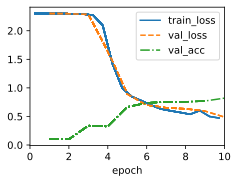

In [79]:
model = GoogLeNet(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

In [80]:
val_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Final validation accuracy: 81.97%


### 8.4.4 Discussion

* Apparently, GoogLeNet is cheaper to compute than predecessors while also improving accuracy

### 8.4.5 Exercises
1. GoogLeNet was so successful that it went through a number of iterations, progressively improving speed and accuracy. Try to implement and run some of them. They include the following:
    1. Add a batch normalization Ioffe.Szegedy.2015, as described later in Batch Norm section.
    1. Make adjustments to the Inception block (width, choice and order of convolutions), as described in Szegedy.Vanhoucke.Ioffe.ea.2016.
    1. Use label smoothing for model regularization, as described in Szegedy.Vanhoucke.Ioffe.ea.2016.
    1. Make further adjustments to the Inception block by adding residual connection Szegedy.Ioffe.Vanhoucke.ea.2017, as described later in ResNet section.
1. What is the minimum image size needed for GoogLeNet to work?
1. Can you design a variant of GoogLeNet that works on Fashion-MNIST's native resolution of $28 \times 28$ pixels? How would you need to change the stem, the body, and the head of the network, if anything at all?
1. Compare the model parameter sizes of AlexNet, VGG, NiN, and GoogLeNet. How do the latter two network
   architectures significantly reduce the model parameter size?
1. Compare the amount of computation needed in GoogLeNet and AlexNet. How does this affect the design of an accelerator chip, e.g., in terms of memory size, memory bandwidth, cache size, the amount of computation, and the benefit of specialized operations?


Exercise #1

* Only try 2 stacking improvements - BatchNorm & ResNet w/ Inception blocks
* Baseline GoogLeNet Val Acc: 81.97%
* GoogLeNet w/ BatchNorm Val Acc: 87.48%
    * Notice how smoother and faster the training and validation losses converge, especially compared to the baseline
* GoogLeNet w/ BatchNorm + Residuals Val Acc: 90.4%

Validation accuracy for GoogLeNet with BatchNorm: 0.8748


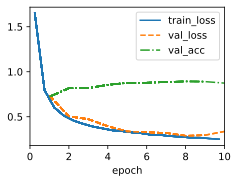

In [53]:
# Part 1: GooLeNet with BatchNorm only
def ConvBatchNormReLUBlock(out_channels, kernel_size=3, stride=1, padding=0):
    branch = nn.Sequential(
        nn.LazyConv2d(out_channels = out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
        nn.LazyBatchNorm2d(), 
        nn.ReLU()
    )
    return branch

class InceptionBatchNorm(nn.Module):
    def __init__(self, c1, c2, c3, c4, **kwargs):
        super().__init__(**kwargs)
        # Branch 1: 1x1 conv
        self.b1 = ConvBatchNormReLUBlock(out_channels=c1, kernel_size=1)
        # Branch 2: 1x1 conv -> 3x3 conv w/ padding=1
        self.b2_1 = ConvBatchNormReLUBlock(out_channels=c2[0], kernel_size=1)
        self.b2_2 = ConvBatchNormReLUBlock(out_channels=c2[1], kernel_size=3, padding=1)
        # Branch 3: 1x1 conv -> 5x5 conv w/ padding=2
        self.b3_1 = ConvBatchNormReLUBlock(out_channels=c3[0], kernel_size=1)
        self.b3_2 = ConvBatchNormReLUBlock(out_channels=c3[1], kernel_size=5, padding=2)
        # Branch 4: 3x3 max pooling -> 1x1 conv
        self.b4_1 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
        self.b4_2 = nn.LazyConv2d(out_channels=c4, kernel_size=1)

    def forward(self, X):
        b1 = self.b1(X)
        b2 = self.b2_2(self.b2_1(X))
        b3 = self.b3_2(self.b3_1(X))
        b4 = self.b4_2(self.b4_1(X))
        return torch.cat((b1, b2, b3, b4), dim=1) # Channel dimension
    

class GoogLeNet_BatchNorm(d2l.Classifier):
    def __init__(self, lr=0.05, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(self.section1(),
                                 self.section2(),
                                 self.section3(),
                                 self.section4(),
                                 self.section5(),
                                nn.LazyLinear(num_classes)
                                )
        self.net.apply(d2l.init_cnn)

    def section1(self):
        b1 = nn.Sequential(
            nn.LazyConv2d(out_channels=64, kernel_size=7, stride=2, padding=3),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return b1

    def section2(self):
        b2 = nn.Sequential(
        nn.LazyConv2d(out_channels=64, kernel_size=1), 
        nn.LazyBatchNorm2d(),
        nn.ReLU(),
        nn.LazyConv2d(out_channels=192, kernel_size=3, padding=1), 
        nn.LazyBatchNorm2d(),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
        return b2

    def section3(self):
        b3 = nn.Sequential(
            Inception(64, (96, 128), (16, 32), 32),
            Inception(128, (128, 192), (32, 96), 64),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return b3
    
    def section4(self):
        b4 = nn.Sequential(
                        Inception(192, (96, 208), (16, 48), 64),
                        Inception(160, (112, 224), (24, 64), 64),
                        Inception(128, (128, 256), (24, 64), 64),
                        Inception(112, (144, 288), (32, 64), 64),
                        Inception(256, (160, 320), (32, 128), 128),
                        nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
        return b4
    
    def section5(self):
        b5 = nn.Sequential(
                        Inception(256, (160, 320), (32, 128), 128),
                        Inception(384, (192, 384), (48, 128), 128),
                        nn.AdaptiveAvgPool2d((1,1)), nn.Flatten())
        return b5

# model = GoogLeNet_BatchNorm().layer_summary((1, 1, 96, 96))

modelGoogLeNetBN = GoogLeNet_BatchNorm(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
modelGoogLeNetBN.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelGoogLeNetBN, data)

val_acc_GoogLeNetBN = evaluate_accuracy(modelGoogLeNetBN, data)
print(f"Validation accuracy for GoogLeNet with BatchNorm: {val_acc_GoogLeNetBN}")

Validation accuracy for Residual Inception with BatchNorm: 90.48%


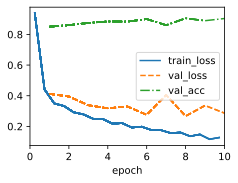

In [58]:
# Part 2: Residual Inception Blocks with BatchNorm (DRY Version)

class ResidualInceptionBN(InceptionBatchNorm):
    def __init__(self, c1, c2, c3, c4, **kwargs):
        super().__init__(c1, c2, c3, c4, **kwargs)

        self.skip_branch = nn.Sequential(
            nn.LazyConv2d(out_channels=(c1 + c2[1] + c3[1] + c4), kernel_size=1),
        )

    def forward(self, X):
        b1 = self.b1(X)
        b2 = self.b2_2(self.b2_1(X))
        b3 = self.b3_2(self.b3_1(X))
        b4 = self.b4_2(self.b4_1(X))
        skip = self.skip_branch(X)

        # Concatenate along channel dimension. Add ReLU asw
        return F.relu(torch.cat([b1, b2, b3, b4], dim=1) + skip) 
    

class GoogLeNet_ResInception_BN(d2l.Classifier):
    def __init__(self, lr=0.01, num_classes=10):
        super().__init__()
        self.save_hyperparameters()

        self.net = nn.Sequential(
            self.section1(),
            self.section2(),
            self.section3(),
            self.section4(),
            self.section5(),
            nn.LazyLinear(num_classes)
        )

    def section1(self):
        return nn.Sequential(
            nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

    def section2(self):
        return nn.Sequential(
            nn.LazyConv2d(64, kernel_size=1),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.LazyConv2d(192, kernel_size=3, padding=1),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

    def section3(self):
        return nn.Sequential(
            ResidualInceptionBN(64, (96, 128), (16, 32), 32),
            ResidualInceptionBN(128, (128, 192), (32, 96), 64),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

    def section4(self):
        return nn.Sequential(
            ResidualInceptionBN(192, (96, 208), (16, 48), 64),
            ResidualInceptionBN(160, (112, 224), (24, 64), 64),
            ResidualInceptionBN(128, (128, 256), (24, 64), 64),
            ResidualInceptionBN(112, (144, 288), (32, 64), 64),
            ResidualInceptionBN(256, (160, 320), (32, 128), 128),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

    def section5(self):
        return nn.Sequential(
            ResidualInceptionBN(256, (160, 320), (32, 128), 128),
            ResidualInceptionBN(384, (192, 384), (48, 128), 128),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )

        
# instanceEx1 = GoogLeNet_ResInception_BN()
# instanceEx1.layer_summary((1, 1, 96, 96))

modelResInceptionBN = GoogLeNet_ResInception_BN(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
modelResInceptionBN.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelResInceptionBN, data)

val_acc_ResInceptionBN = evaluate_accuracy(modelResInceptionBN, data)
print(f"Validation accuracy for Residual Inception with BatchNorm: {val_acc_ResInceptionBN * 100:.2f}%")


Exercise #2

* Minimum image size needed for GoogLeNet (reference og GoogLeNet Design)
* $3\times 3$ Maxpool w/ Stride 2, Padding 1: Roughly 2-fold decrease in height/width spatial dim.
* $3\times 3$ Maxpool w/ Stride 2, Padding 1: Roughly 2-fold decrease in height/width spatial dim.
* $3\times 3$ Maxpool w/ Stride 2, Padding 1: Roughly 2-fold decrease in height/width spatial dim.
* $3\times 3$ Maxpool w/ Stride 2, Padding 1: Roughly 2-fold decrease in height/width spatial dim.
* Global Average Pool

* The dimensions chosen in the demonstration of a input spatial dimension of $96 \times 96$ is reasonable, as a total downsample of 16-fold will result in spatial dimension of $6\times 6$ before the global average pool. Note, $6$ is not a hard theoretical limit, but reasonable given the circumstance. Also note, the layer summary of the GoogLeNet shows $3\times 3$, and im guessing the extra factor of 2 comes from the stride=2 in the very first conv layer. 


Exercise #3
* Basically, change the stride of the first conv layer to 1 to ensure no spatial dimension reduction
* Reduce number of maxpool layers/components to 2
* Group Inception blocks into say 3 and 4 where there is a maxpool in between the inception groups (less than 2 + 5 + 2 = 9 from earlier - to prevent overfitting. Tried 9 first and val loss and val acc was indicating overfitting)
* 28x28 val acc: 89.56%
    * w/ BatchNorm & Residual Connections
* 96x96 val acc: 90.48% (Exercise 1)
    * w/ BatchNorm & Residual Connections


Validation accuracy for GoogLeNet 28: 87.02%


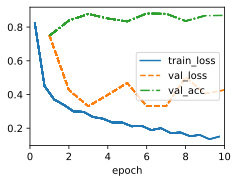

In [ ]:
# Ignore this cell. Go to the one below
class GoogLeNet_28dim(d2l.Classifier):
    def __init__(self, lr=0.01, num_classes=10):
        super().__init__()
        self.save_hyperparameters()

        self.net = nn.Sequential(
            self.section1(),
            self.section2(),
            self.section3(),
            nn.LazyLinear(num_classes)
        )

    def section1(self):
        branch1 = nn.Sequential(
            nn.LazyConv2d(64, kernel_size=7, stride=1, padding=3),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.LazyConv2d(128, kernel_size=5, stride=1, padding=2),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return branch1
        
    
    def section2(self):
        branch2 = nn.Sequential(
            ResidualInceptionBN(64, (96, 128), (16, 32), 32),
            ResidualInceptionBN(128, (128, 192), (32, 96), 64),
            ResidualInceptionBN(192, (96, 208), (16, 48), 64),
            ResidualInceptionBN(160, (112, 224), (24, 64), 64), 
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return branch2
    
    def section3(self):
        branch3 = nn.Sequential(
            ResidualInceptionBN(128, (128, 256), (24, 64), 64),
            ResidualInceptionBN(112, (144, 288), (32, 64), 64),
            ResidualInceptionBN(256, (160, 320), (32, 128), 128),
            ResidualInceptionBN(256, (160, 320), (32, 128), 128),
            ResidualInceptionBN(256, (160, 320), (32, 128), 128),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        return branch3
    
modelGoogLeNet28 = GoogLeNet_28dim(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(28, 28))
modelGoogLeNet28.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelGoogLeNet28, data)

val_acc_GoogLeNet28 = evaluate_accuracy(modelGoogLeNet28, data)
print(f"Validation accuracy for GoogLeNet 28: {val_acc_GoogLeNet28 * 100:.2f}%")

Validation accuracy for GoogLeNet 28: 89.56%


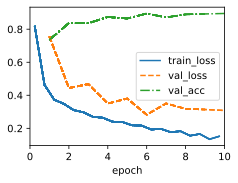

In [66]:
class GoogLeNet_28dim(d2l.Classifier):
    def __init__(self, lr=0.01, num_classes=10):
        super().__init__()
        self.save_hyperparameters()

        self.net = nn.Sequential(
            self.section1(),
            self.section2(),
            self.section3(),
            nn.LazyLinear(num_classes)
        )

    def section1(self):
        branch1 = nn.Sequential(
            nn.LazyConv2d(64, kernel_size=7, stride=1, padding=3),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.LazyConv2d(128, kernel_size=5, stride=1, padding=2),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            # nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return branch1
        
    
    def section2(self):
        branch2 = nn.Sequential(
            ResidualInceptionBN(64, (96, 128), (16, 32), 32),
            ResidualInceptionBN(128, (128, 192), (32, 96), 64),
            ResidualInceptionBN(192, (96, 208), (16, 48), 64),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return branch2
    
    def section3(self):
        branch3 = nn.Sequential(
            ResidualInceptionBN(128, (128, 256), (24, 64), 64),
            ResidualInceptionBN(112, (144, 288), (32, 64), 64),
            ResidualInceptionBN(256, (160, 320), (32, 128), 128),
            ResidualInceptionBN(256, (160, 320), (32, 128), 128),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        return branch3
    
modelGoogLeNet28 = GoogLeNet_28dim(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(28, 28))
modelGoogLeNet28.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelGoogLeNet28, data)

val_acc_GoogLeNet28 = evaluate_accuracy(modelGoogLeNet28, data)
print(f"Validation accuracy for GoogLeNet 28: {val_acc_GoogLeNet28 * 100:.2f}%")

Exercise #4
* See answer below for Ex.5

Exercise #5
* Im kinda sick of doing all these calculations for parameter count and compute needed so will skip. Not a good use of my time
* Based on previous intuition, GoogLeNet is dominante by conv layers, with the only linear layer being the final output one, so it will take less memory than AlexNet, but more compute to train/run

# 8.5 Batch Normalization
* Method to help deep networks (>100 layers) converge
* Inherent regularization effect

### 8.5.1 Training Deep Networks
* Recall for MLP on predicting house prices, first step when working with real data was to standardize features such that they have mean of 0 and unit variance
* Such a technique like this helps keep the estimation problem well controlled
* Useful for optimizer since it puts parameters on a similar scale
* During training process, possible that parameters may take a wide variety of values, within or between different layers
* Could be mitigated/addressed by adaptive learning rates
* Noise injection also helps as a form of regularizaiton and helps prevent overfitting
* Batch Normalization has all 3 benefits (1) Preprocessing, (2) Numerical stability, (3) Regularization

* Can be applied to individual layers we specify, or all of them if we choose
* Uring training, For each incoming minibatch input, subtract the mean and divide by the standard deviation
* We also apply a scale coefficient and an offset to recover the lost degrees of freedom (shift for mean, scale for variance, since information about them was lost during normalization)
* Note, it is impossible to do BatchNorm with a batch size of 1. Will see later that large enough minibatches is stable and effective
* Variable magnitudes for intermiediate/hitten layers cannot diverge during training since BatchNorm actively recenters and rescales them each time. Based on experience, batch norm seems to allow for more aggressive learning rates 
* Empirically, minibatch sizes of 50-100 seem to work the best for BatchNorm
* Might think want to use entire dataset to estimate mean & variance, to remove dependence of batch normalization statistics on which batch it happened to be assigned to. DUring training, this is infeasbilt because the values for the dataset change everytime we update our model with SGD. HOwever, once the model is trained, we can calculate the means and variances of each layers' variables based on the entire dataset
    * Training Mode: Normalized by minibatch statistics
    * Prediction Mode: Normalized by dataset statistics

$$ \text{BN}(x) = \gamma \odot  \frac{x - \hat{\mu_{\mathcal{B}}}}{\hat{\sigma_{\mathcal{B}}}} + \beta$$
* BN: Batch Normalization Operation
* $\mathcal{B}$: Minibatch
* $x$: $x\in \mathcal{B}$ s.t. it is an input to Batch Normalization 
* $\hat{\mu_{\mathcal{B}}} = \frac{1}{|\mathcal{B}|} \sum_{x\in \beta}$: Sample Mean
* $\hat{\sigma_{\mathcal{B}}} = \frac{1}{|\beta|} \sum_{x\in \mathcal{B}} (x - \hat{\mu_{\mathcal{B}}})^2 + \epsilon$: Sample Standard Deviation, where $\epsilon$ is to ensure we never divide by zero, in the event a particular batch has very small or zero variance
* $\beta$: Shift Learnable Parameter
* $\gamma$: Scale Learnable Parameter

### 8.5.2 Batch Normalization Layers

BatchNorm implementation details differ for FC and Conv layers, main point being FC operates on an entire minimatch at a time, we cannot ignore the batch dimension as we previously did when discussing other NN Building Blocks

Batch Normalization for Fully-Connected Layers
* In original 2015 paper, used batch normalizatino after affine transformation ($Wx+b$) (multiplicative weights + additive biases) and before the nonlinear activation function $\phi$. The $h$ means the output of the fully connected layer
$$ h = \phi(\text{BN}(Wx+b))$$
* Later exepriments were done with batchnorm after both the affine transform + nonlinear activation
* Recall: Mean & Variance are calculated on same minibatch on which affine transform is applied

Batch Normalization for Convolutional Layers
* Apply Batch Normalization after convolution, but before the nonlinear activation 
* Batch Normalizatino is applied on a per-channel basis across all locations (consistent with translation invariance i.e. not appling across height or width dimension)
* Assume minibatches have $m$ examples and for each channel, the output convolution has height $p$ and width $q$. Thus, we will carry out batch normalization over $m\cdot p \cdot q$ elements per output channel simultaneously
    * Collect values over all spatial locations across all examples when computing mean and variance
    * Apply normalization - thus each channel will have its own set of shift & scale learnable parameters

Layer Normalization 
* Note in context of convolutions, batch norm can still be applied for minibatches of size 1 (all the spatial locations of the output of each channel)
* Layer Normalization works just like BatchNorm in idea, but applied to one obervation at a time where both offset and scaling factors are scalars
* For an $n$-dimensional vector $x$, layer norms are given by:
$$ x \rightarrow \text{LN}(x) = \frac{x - \hat{\mu}}{\hat{\sigma}}$$
$$ \hat{\mu} \equiv \frac{1}{n} \sum_{i=1}^n x_i \text{  and  } \hat{\sigma}^2 = \frac{1}{2} \sum_{i=1}^n (x_i - \hat{\mu})^2 + \epsilon$$
where $\epsilon$ is for numerical stability
* Benefit of Layer Normalization is it prevents divervgence in that the operation is scale independent in that $\text{LN}(x) \approx \text{LN}(\alpha x)$ where the approximate sign is for the $\epsilon$. It also dosen't depend on minibatch size, and thus dosen't matter if we are in training/prediction


Batch Normalization During Prediction
* If we are only seeing 1 observation at a time during test/prediction, we do not have a minibatch on which to calculate statistics over
* Typically, minibatch statistics (shift and scale parameters are learned) are calculated from training set and fixed at test/prediction time

### 8.5.3 Implementation from Scratch

In [78]:
def batch_norm(X, gamma, beta, moving_mean, moving_var, eps, momentum):
    # Note, the "momentum" here is not the same as momentum in optimization (like Adam)

    # Use is_grad_enabled to determine whether we are in training or prediction mode 
    if not torch.is_grad_enabled(): # Prediction Mode
        X_hat = (X - moving_mean) / torch.sqrt(moving_var + eps)
    else: # Training mode
        assert len(X.shape) in (2, 4) # only handling FC or Conv layer inputs
        if len(X.shape) == 2: # FC Layer
            mean = X.mean(dim=0)
            var = ( (X - mean) ** 2).mean(dim=0)
        else: # Conv Layer
            # Calculate mean and variance on channel dim (axis=1) and keepdim=True
            # to ensure same shape as X for broadcasting in normalization step
            mean = X.mean(dim=(0, 2, 3), keepdim=True)
            var = ( (X - mean) ** 2).mean(dim=(0, 2, 3), keepdim=True)
        # Training mode - current mean and variance are used
        X_hat = (X - mean) / torch.sqrt(var + eps)

        # Update moving mean and variance using moving average
        moving_mean = (1.0 - momentum) * moving_mean + momentum * mean
        moving_var = (1.0 - momentum) * moving_var + momentum * var
    Y = gamma * X_hat + beta # Scale and shift w/ learnable params
    return Y, moving_mean, moving_var


In [82]:
class BatchNorm(nn.Module):
    """
    num_features: Number of outputs for a FC layer / number of output channels for Conv Layer
    num_dims: 2 for FC layer, 4 for Conv layer
    """
    def __init__(self, num_features, num_dims):
        super().__init__()
        if num_dims == 2: # FC Layer
            shape = (1, num_features)
        else: # Conv Layer
            shape = (1, num_features, 1, 1)
        self.gamma = nn.Parameter(torch.ones(shape)) # Scale Learnable parameter
        self.beta = nn.Parameter(torch.zeros(shape)) # Shift Learnable parameter
        
        # These 2 are NOT learnable, but updated during training and frozen during prediction
        self.moving_mean = torch.zeros(shape) 
        self.moving_var = torch.ones(shape) 

    def forward(self, X):
        # Move moving_mean and moving_var to same device where X (input) is located
        if self.moving_mean.device != X.device:
            self.moving_mean = self.moving_mean.to(X.device)
            self.moving_var = self.moving_var.to(X.device)

        # Save the updated moving_mean and moving_var
        Y, self.moving_mean, self.moving_var = batch_norm(
            X, self.gamma, self.beta, self.moving_mean,
            self.moving_var, eps=1e-5, momentum=0.1)
        return Y

### 8.5.4 LeNet with Batch Normalization
* Recall, BatchNorm after the Affine Transform/Conv Filters, but before the nonlinear activation

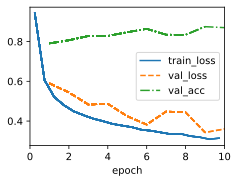

In [83]:
class BNLeNetScratch(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5), BatchNorm(6, num_dims=4),
            nn.Sigmoid(), nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(16, kernel_size=5), BatchNorm(16, num_dims=4),
            nn.Sigmoid(), nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(), nn.LazyLinear(120),
            BatchNorm(120, num_dims=2), nn.Sigmoid(), nn.LazyLinear(84),
            BatchNorm(84, num_dims=2), nn.Sigmoid(),
            nn.LazyLinear(num_classes))
        
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
model = BNLeNetScratch(lr=0.1)
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

In [84]:
vac_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * vac_acc:.2f}%")

Final validation accuracy: 87.00%


In [ ]:
# Should be 6 each for each output channel of first Conv layer
model.net[1].gamma.reshape((-1,)), model.net[1].beta.reshape((-1,))

(tensor([1.9945, 1.5896, 1.8158, 1.7239, 1.6967, 2.3927], device='cuda:0',
        grad_fn=<ViewBackward0>),
 tensor([-1.4189, -0.6503, -0.8547,  0.1071,  0.3089, -1.2998], device='cuda:0',
        grad_fn=<ViewBackward0>))

In [ ]:
# 16, for each output channel fo 2nd Conv layer
model.net[5].gamma.reshape((-1,)), model.net[5].beta.reshape((-1,))

(tensor([1.4798, 1.2524, 1.2761, 1.4202, 1.2983, 1.3677, 1.2252, 1.1829, 1.3888,
         1.4726, 1.0418, 1.3948, 1.4271, 1.6104, 1.3907, 1.5596],
        device='cuda:0', grad_fn=<ViewBackward0>),
 tensor([ 0.2726,  0.2360, -0.0517,  0.3196,  0.1509,  0.3150, -0.1532, -0.1281,
          0.4725, -0.2809, -0.0213, -0.2251,  0.1805, -0.0402,  0.3114, -0.2126],
        device='cuda:0', grad_fn=<ViewBackward0>))

### 8.5.5 Concise Implementation

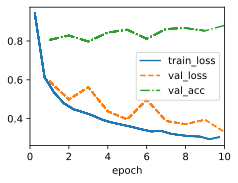

In [69]:
class BNLeNet(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5), nn.LazyBatchNorm2d(),
            nn.Sigmoid(), nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(16, kernel_size=5), nn.LazyBatchNorm2d(),
            nn.Sigmoid(), nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(), nn.LazyLinear(120), nn.LazyBatchNorm1d(),
            nn.Sigmoid(), nn.LazyLinear(84), nn.LazyBatchNorm1d(),
            nn.Sigmoid(), nn.LazyLinear(num_classes))
        
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
model = BNLeNet(lr=0.1)
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

In [70]:
vac_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * vac_acc:.2f}%")

Final validation accuracy: 87.99%


### 8.5.6 Discussion

* Intutuition - batch normalizaiton makes optimization landscape smoother
* Be wary about hand-wavy, speculative intuition vs true explanation for empirical phenomena when training/testing deep neural networks 
    * Recall, even without dropout and weight decay, their flexible nature allows them to overfit to training data, that their ability to generalize to unseen data needs much more refined, robust, sensible learning-theoretic generalizaiton garuntees
* Original 2016 BatchNorm paper offered explanatino for "reducing internal covariate shift"
    * Presumably referred to notion of distributino of variable changes over the course of training
    * Problem 1: This drift is different from covariate shift, making the naming scheme misleading
    * Problem 2: Explaination offers under-specified intuition aobut why it works 
* "Internal Covariate Shift" is no more worthy of criticism than supposedly thousands of vague claims made in ML research literature

Batch Norm Summary
* During training, batch norm continuously adjust intermediate outputs of the network by applying normalization by the mean and std of current minibatch, leading to more stable neural network values
* Batch norm is slightly different for FC and Conv layers
    * for Conv layers, layer norm can be used as an alternative (conv layers can do batchnorm with minibatches of size 1)
* Like dropout, batch norm layers behave differently during training and prediction
* Batch norm has dual purpose of regularizatino technique and aiding convergence in optimization 
    * Note, original motivation of "reducing internal covariate shift" seems misleading/invalid/retroactive
* Consider removing batch norm to make models more robust to input perturbations


### 8.5.7 Exercises
1. Should we remove the bias parameter from the fully connected layer or the convolutional layer before the batch normalization? Why?
1. Compare the learning rates for LeNet with and without batch normalization.
    1. Plot the increase in validation accuracy.
    1. How large can you make the learning rate before the optimization fails in both cases?
1. Do we need batch normalization in every layer? Experiment with it.
1. Implement a "lite" version of batch normalization that only removes the mean, or alternatively one that
   only removes the variance. How does it behave?
1. Fix the parameters `beta` and `gamma`. Observe and analyze the results.
1. Can you replace dropout by batch normalization? How does the behavior change?
1. Research ideas: think of other normalization transforms that you can apply:
    1. Can you apply the probability integral transform?
    1. Can you use a full-rank covariance estimate? Why should you probably not do that? 
    1. Can you use other compact matrix variants (block-diagonal, low-displacement rank, Monarch, etc.)?
    1. Does a sparsification compression act as a regularizer?
    1. Are there other projections (e.g., convex cone, symmetry group-specific transforms) that you can use?

Exercise #1
* Yes, we should remove the bias parameter from FC/Conv layer before BatchNorm since the need for it is made redundant by the learned shift parameter in the BatchNorm layer 
* "Default" pre-BatchNorm transform: $z=Wx+b$
* $BN(x) = \gamma \odot \frac{x-\mu}{\sigma + \epsilon} + \beta$
    * $\mu = \mathbb{E}[Wx+b] = \mathbb{E}[Wx] + b $
    * $ z - \mu = (Wx+b) - (\mathbb{E}[Wx] + b) = Wx - \mathbb{E}[Wx]$
    * Notice how bias terms cancel out

Exercise #2
* Default LeNet-5 Val Acc: 72.94%
* LeNet-5 w/ BN Val Acc: 87.46%


Default LeNet Validation Accuracy: 0.7294


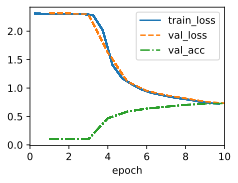

In [ ]:
# Default LeNet-5

class LeNet(d2l.Classifier):
    """The LeNet-5 model with NO BatchNorm layers"""
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5, padding=2), 
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(16, kernel_size=5), 
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.LazyLinear(120), 
            nn.Sigmoid(),
            nn.LazyLinear(84), 
            nn.Sigmoid(),
            nn.LazyLinear(num_classes))
        
        
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
modelDefaultLeNet = LeNet(lr=0.1)
modelDefaultLeNet.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelDefaultLeNet, data)

DefLeNetValAcc = evaluate_accuracy(modelDefaultLeNet, data)
print(f"Default LeNet Validation Accuracy: {DefLeNetValAcc}")


LeNet with BatchNorm Validation Accuracy: 87.46%


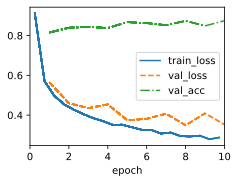

In [74]:
class LeNetBN(d2l.Classifier):
    """The LeNet-5 model WITH BatchNorm layers before every activation function
    for both FC and Conv Layers"""
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5, padding=2), 
            nn.LazyBatchNorm2d(),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(16, kernel_size=5), 
            nn.LazyBatchNorm2d(),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.LazyLinear(120), 
            nn.LazyBatchNorm1d(),
            nn.Sigmoid(),
            nn.LazyLinear(84), 
            nn.LazyBatchNorm1d(),
            nn.Sigmoid(),
            nn.LazyLinear(num_classes))
        
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
modelLeNetBN = LeNetBN(lr=0.1)
modelLeNetBN.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelLeNetBN, data)

LeNetBNValAcc = evaluate_accuracy(modelLeNetBN, data)
print(f"LeNet with BatchNorm Validation Accuracy: {LeNetBNValAcc*100:.2f}%")

Exercise #3
* LeNet5 w/o BatchNorm (i.e. default version from Ex2) val acc: 72.94%
* LeNet5 w/ BatchNorm on every Conv & FC layer (from Ex2) val acc: 87.46%
* LeNet5 w/ BatchNorm only on first 2 conv layers val acc: 83.49%
* LeNet5 w/ BatchNorm only on first 2 FC layers val acc: 67.49%
    * Worse than the default baseline with no BatchNorm layers at all
    * Very unstable training
* Should have BatchNorm layers at all FC/Conv layers for main benefit
* Significant gains in val acc can be made from just adding BatchNorm layers for the Conv layers only
* Adding BatchNorm layers to FC layers only makes training stability & performance worse

LeNet with BatchNorm on Conv Layers Validation Accuracy: 83.49%


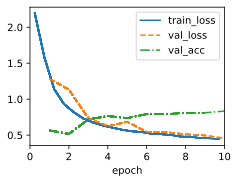

In [75]:
# LeNet-5 with BatchNorm only on Conv Layers

class LeNetEx3V1(d2l.Classifier):
    """The LeNet-5 model WITH BatchNorm layers before every activation function
    for both FC and Conv Layers"""
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5, padding=2), 
            nn.LazyBatchNorm2d(),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(16, kernel_size=5), 
            nn.LazyBatchNorm2d(),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.LazyLinear(120),
            nn.Sigmoid(),
            nn.LazyLinear(84), 
            nn.Sigmoid(),
            nn.LazyLinear(num_classes))
        
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
modelLeNetEx3V1 = LeNetEx3V1(lr=0.1)
modelLeNetEx3V1.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelLeNetEx3V1, data)

LeNetEx3V1ValAcc = evaluate_accuracy(modelLeNetEx3V1, data)
print(f"LeNet with BatchNorm on Conv Layers Validation Accuracy: {LeNetEx3V1ValAcc*100:.2f}%")

LeNet with BatchNorm on FC Layers Validation Accuracy: 67.49%


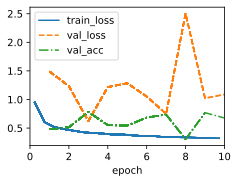

In [76]:
# LeNet-5 with BatchNorm only on FC Layers

class LeNetEx3V2(d2l.Classifier):
    """The LeNet-5 model WITH BatchNorm layers before every activation function
    for both FC and Conv Layers"""
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5, padding=2), 
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(16, kernel_size=5), 
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.LazyLinear(120),
            nn.LazyBatchNorm1d(),
            nn.Sigmoid(),
            nn.LazyLinear(84), 
            nn.LazyBatchNorm1d(),
            nn.Sigmoid(),
            nn.LazyLinear(num_classes))
        
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
modelLeNetEx3V2 = LeNetEx3V2(lr=0.1)
modelLeNetEx3V2.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelLeNetEx3V2, data)

LeNetEx3V2ValAcc = evaluate_accuracy(modelLeNetEx3V2, data)
print(f"LeNet with BatchNorm on FC Layers Validation Accuracy: {LeNetEx3V2ValAcc*100:.2f}%")

Exercise #4
* Removed the variance division, kept the mean shift
* Default LeNet val acc: 72.94%
* Full BatchNorm LeNet val acc: 87.00%
* Ex4 LeNet val acc: 82.47%
    * Notice it still provides some benefits, but short of its "full potential"

Validation accuracy for modelEx4: 82.47%


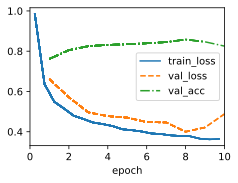

In [81]:
def batch_normEx4(X, gamma, beta, moving_mean, moving_var, eps, momentum):
    """Coped from 8.5.3 and Stripped down to remove variance normalization and just keep mean shift"""
    if not torch.is_grad_enabled(): 
        X_hat = (X - moving_mean) / torch.sqrt(moving_var + eps)
    else: 
        assert len(X.shape) in (2, 4) 
        if len(X.shape) == 2:
            mean = X.mean(dim=0)
        else: 
            mean = X.mean(dim=(0, 2, 3), keepdim=True)
            var = ( (X - mean) ** 2).mean(dim=(0, 2, 3), keepdim=True)
        # Training mode - current mean and variance are used
        X_hat = (X - mean) 

        # Update moving mean and variance using moving average
        moving_mean = (1.0 - momentum) * moving_mean + momentum * mean
        moving_var = (1.0 - momentum) * moving_var + momentum * var
    Y = gamma * X_hat + beta # Scale and shift w/ learnable params
    return Y, moving_mean, moving_var


class BatchNormEx4(nn.Module):
    """
    Copied from earlier

    requires_grad=False for gamma and beta to fix them
    """
    def __init__(self, num_features, num_dims):
        super().__init__()
        if num_dims == 2: # FC Layer
            shape = (1, num_features)
        else: # Conv Layer
            shape = (1, num_features, 1, 1)
        self.gamma = nn.Parameter(torch.ones(shape), requires_grad=False) # Scale Learnable parameter
        self.beta = nn.Parameter(torch.zeros(shape), requires_grad=False) # Shift Learnable parameter
        
        # These 2 are NOT learnable, but updated during training and frozen during prediction
        self.moving_mean = torch.zeros(shape) 
        self.moving_var = torch.ones(shape) 

    def forward(self, X):
        # Move moving_mean and moving_var to same device where X (input) is located
        if self.moving_mean.device != X.device:
            self.moving_mean = self.moving_mean.to(X.device)
            self.moving_var = self.moving_var.to(X.device)

        # Save the updated moving_mean and moving_var
        Y, self.moving_mean, self.moving_var = batch_norm(
            X, self.gamma, self.beta, self.moving_mean,
            self.moving_var, eps=1e-5, momentum=0.1)
        return Y
    

class LeNetEx4(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5), BatchNormEx4(6, num_dims=4),
            nn.Sigmoid(), nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(16, kernel_size=5), BatchNormEx4(16, num_dims=4),
            nn.Sigmoid(), nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(), nn.LazyLinear(120),
            BatchNormEx4(120, num_dims=2), nn.Sigmoid(), nn.LazyLinear(84),
            BatchNormEx4(84, num_dims=2), nn.Sigmoid(),
            nn.LazyLinear(num_classes))
        
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
modelEx4 = LeNetEx4(lr=0.1)
modelEx4.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelEx4, data)

ex4_val_acc = evaluate_accuracy(modelEx4, data)
print(f"Validation accuracy for modelEx4: {ex4_val_acc*100:.2f}%")

Exercise #5
* Does not look like nn.LazyBatchNorm has settings to fix beta and gamma, only turn on/off the running mean and variance statistic tracker. 
* Set requires_grad=False for custom BatchNorm implemented above
* Resultant validation accuracy of: 84.60%
    * Compares with default LeNet5 val acc of: 72.94%
    * Comparse with "full" batchnorm from earlier in textbook demo val acc of: 87.00%
* Can still get significant benefit without the learnable shift & scale parameters, but not able to capture the "full benefits", showing important of those 2 learnable parameters

Validation accuracy for modelEx5: 84.60%


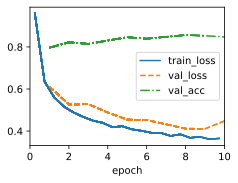

In [79]:
class BatchNormEx5(nn.Module):
    """
    Copied from earlier

    requires_grad=False for gamma and beta to fix them
    """
    def __init__(self, num_features, num_dims):
        super().__init__()
        if num_dims == 2: # FC Layer
            shape = (1, num_features)
        else: # Conv Layer
            shape = (1, num_features, 1, 1)
        self.gamma = nn.Parameter(torch.ones(shape), requires_grad=False) # Scale Learnable parameter
        self.beta = nn.Parameter(torch.zeros(shape), requires_grad=False) # Shift Learnable parameter
        
        # These 2 are NOT learnable, but updated during training and frozen during prediction
        self.moving_mean = torch.zeros(shape) 
        self.moving_var = torch.ones(shape) 

    def forward(self, X):
        # Move moving_mean and moving_var to same device where X (input) is located
        if self.moving_mean.device != X.device:
            self.moving_mean = self.moving_mean.to(X.device)
            self.moving_var = self.moving_var.to(X.device)

        # Save the updated moving_mean and moving_var
        Y, self.moving_mean, self.moving_var = batch_norm(
            X, self.gamma, self.beta, self.moving_mean,
            self.moving_var, eps=1e-5, momentum=0.1)
        return Y
    

class LeNetEx5(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5), BatchNormEx5(6, num_dims=4),
            nn.Sigmoid(), nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(16, kernel_size=5), BatchNormEx5(16, num_dims=4),
            nn.Sigmoid(), nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(), nn.LazyLinear(120),
            BatchNormEx5(120, num_dims=2), nn.Sigmoid(), nn.LazyLinear(84),
            BatchNormEx5(84, num_dims=2), nn.Sigmoid(),
            nn.LazyLinear(num_classes))
        
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
modelEx5 = LeNetEx5(lr=0.1)
modelEx5.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelEx5, data)

ex5_val_acc = evaluate_accuracy(modelEx5, data)
print(f"Validation accuracy for modelEx5: {ex5_val_acc*100:.2f}%")

Exercise #6
* Skip for now. Not in the mood

Exercise #7 
* Research question. Skip for now. Gonna take a while and not urgent for understanding. Made note of them in Word Tracker file

# 8.6. Residual Networks (ResNet) and ResNeXt

* Try to understand how adding layers can increase complexity & expressiveness of network
* Ability to design network where adding layers make netwroks strictly more expressive rather than just different

In [90]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

### 8.6.1 Function Classes

* Consider the class of functions a specific network architecture can attain (given hyperparameter settings), which we will call $\mathcal{F}$
* $f^*$  is the "truth" function we would like to find / the network to learn/approximate
* However, no gararuntee that the $f^* \in \mathcal{F}$. Our best bet is $f_{\mathcal{F}}^* \in \mathcal{F}$ by solving: 
$$ f_{\mathcal{F}}^* \equiv \text{argmin}_f L(X, y, f) \text{ subject to } f \in \mathcal{F}$$
* Regularization can control the complexity of $\mathcal{F}$
* Reasonable to assume that a more powerful architecture would lead to a better outcome, corresponding to class of functions $\mathcal{F}'$ i.e. $f_{\mathcal{F}'}^*$ should be "better" approximation for $f^*$ than $f_{\mathcal{F}}^*$
* Note, this is not garunteed, if the function classes are not nested ($\mathcal{F} \not \subset \mathcal{F}'$)
    * Figure below is a good visual of this, where the extra complexity/expressiveenss of a candidate network can result in the set of functions moving away from the truth function. 
* Howver, this garuntee can be achieved if we demand that $\mathcal{F}_1 \subseteq \dots \subseteq \mathcal{F}_6$
* In practice, this would be implemented by depanding that a newly added layer/block to a neural network be trained into/to contain the identity function $f(x) = x$, which will make the new network contain the old network, which allows it to better approximate the trianing set, without diverging/straying and helps reduce training errors

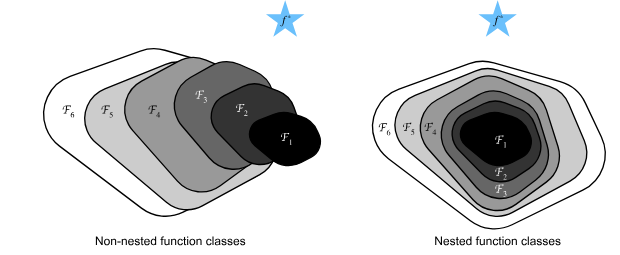

### 8.6.2 Residual Blocks

* $f(x)$ is the transformation/mapping we want to learn (to feed into the nonlinear activation)
* LHS (w/out Residual Mapping): Block denoted by the dotted block must directly learn the entire $f(x)$
* RHS (w/ the Residual Mapping): Block denoted by dotted line only has to learn the residual of the block i.e. $g(x) = f(x) - x$
    * Note that this inherently includes the identity mapping, corresponding to $g(x) = 0$
    * Can also be thought of as a type of Inception block w/ multiple branches

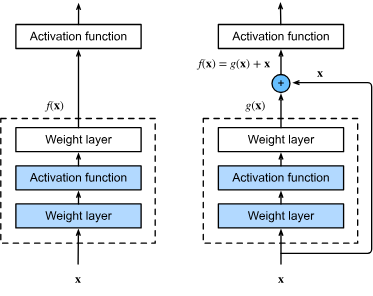

In a regular block (left), the portion within the dotted-line box must directly learn the mapping $\mathit{f}(\mathbf{x})$. In a residual block (right), the portion within the dotted-line box needs to learn the residual mapping $\mathit{g}(\mathbf{x}) = \mathit{f}(\mathbf{x}) - \mathbf{x}$, making the identity mapping $\mathit{f}(\mathbf{x}) = \mathbf{x}$ easier to learn.


* Residual Block Design
    * Two $3\times 3$ convolutional layer with same number of output channels
    * Each conv layer is followed by batch norm layer, 
    * At output of the above, we add in the initial input
    * Block ends with ReLU layer
* Note that the addition of the input to the output of the conv layers require that they be of the same dimension. 
    * If we wanted to change number of channels (in the conv layers), we need to introduce an additional $1\times 1$ conv layer in the residual-connection branch to transform the input into the same shape as the output of the conv layers

In [92]:
class Residual(nn.Module):
    def __init__(self, num_channels, use_1x1conv=False, strides=1):
        super().__init__()
        self.conv1 = nn.LazyConv2d(num_channels, kernel_size=3, padding=1, stride=strides)
        self.bn1 = nn.LazyBatchNorm2d()
        self.conv2 = nn.LazyConv2d(num_channels, kernel_size=3, padding=1)
        self.bn2 = nn.LazyBatchNorm2d()

        if use_1x1conv:
            self.conv3 = nn.LazyConv2d(num_channels, kernel_size=1, stride=strides)
        else:
            self.conv3 = None


    def forward(self, X):
        Y = F.relu(self.bn1(self.conv1(X)))
        Y = self.bn2(self.conv2(Y))
        if self.conv3:
            X = self.conv3(X)
        Y += X
        return F.relu(Y)


In [93]:
# Case where input & output are the same shape, thus no 1x1 conv needed for skip branch
blk = Residual(3)
X = torch.randn(4, 3, 6, 6)
blk(X).shape

torch.Size([4, 3, 6, 6])

In [95]:
# Case where output dimensions are halved and channel count is increased
blk = Residual(6, use_1x1conv=True, strides=2)
blk(X).shape

torch.Size([4, 6, 3, 3])

### 8.6.3 ResNet Model

* First two layers of ResNet
    * $7\times 7$ Conv layer w/ 64 output channels, stride of 2, followed by $3 \times 3$ max-pool w/ stride 2 (Like GoogLeNet)
    * Batch Norm layer added after each conv layer in ResNet
* 4 Modules of Residual Blocks, each with same number of output channels. Number of output channels in first module is same as number of input channels (GoogLeNet used 4 modules of Inception blocks)
    * For each Residual Block, the height and widths are halved, while the number of channels is doubled 
* Ends with Global Average Pooling and Fully Connected Layer Output
* ResNet-18 Namesake
    * 1 $7\times 7$ Convolutional 
    * 4 Modules with 4 #3\times 3$ Convolutional Layers Each
    * Final FC Layer
    * NOTE: Ignore $1\times 1$ conv layers in skip-connection branches to this count

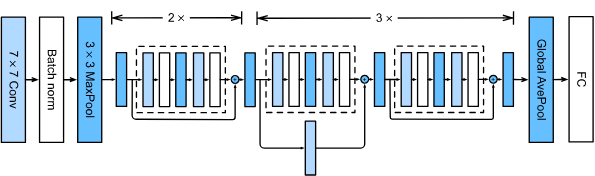

In [ ]:
class ResNet(d2l.Classifier):
    def __init__(self, arch, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(self.b1())

        for i, b in enumerate(arch):
            self.net.add_module(f'b{i+2}', self.block(*b, first_block=(i==0)))

        self.net.add_module('last', nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
            nn.LazyLinear(num_classes)))
        
        self.net.apply(d2l.init_cnn)


    def b1(self):
        block1 = nn.Sequential(
            nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3),
            nn.LazyBatchNorm2d(), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
        return block1


    def block(self, num_residuals, num_channels, first_block=False):
        blk = []
        for i in range(num_residuals):
            if i == 0 and not first_block:
                blk.append(Residual(num_channels, use_1x1conv=True, strides=2))
            else:
                blk.append(Residual(num_channels))
        return nn.Sequential(*blk)

In [97]:
# ResNet-18 instance of ResNet class
# See how input shapes change across modules, output channel increases, and resolution decreases
class ResNet18(ResNet):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__(((2, 64), (2, 128), (2, 256), (2, 512)),
                       lr, num_classes)

ResNet18().layer_summary((1, 1, 96, 96))

Sequential output shape:	 torch.Size([1, 64, 24, 24])
Sequential output shape:	 torch.Size([1, 64, 24, 24])
Sequential output shape:	 torch.Size([1, 128, 12, 12])
Sequential output shape:	 torch.Size([1, 256, 6, 6])
Sequential output shape:	 torch.Size([1, 512, 3, 3])
Sequential output shape:	 torch.Size([1, 10])


### 8.6.4 Training

* Note difference between training and validation loss, but validation accuracy is still good
* ResNet is a quite powerful and flexible architecture, so more training data would offer distinct benefit in closing gap and improving accuracy asw
    * High accuracy means models' prediction for correct category is still higher than all other alteratives, but higher validation loss implies less condfidence (i.e. prediction for correct class is still higher than all other classes, but not dominant w.r.t. other classes) 

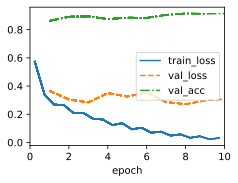

In [98]:
model = ResNet18(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

### 8.6.5 ResNeXt
* In design of ResNets, there is a trade-off between nonlinearties and dimensionality within a given block. Recall nonlinearities are added after each convolutional layer, but each residual block increases the number of output channels
    * To add more nonlinearities, we can increase the number of conv layers or the width of the convolutions
    * Or, another method for more nonlinearties is the increase in number of channels that can carry information between blocks. Note this has quadratic computational cost (outputs from this block, inputs from next block)
* Take inspiration from Inception block w/ its multiple branches, lead to design of ResNeXt
    * Have information flowing through the block in separate branches
    * Have same transformation in all branches, thus minimzing need for manual (hyperparameter) tuning of each branch

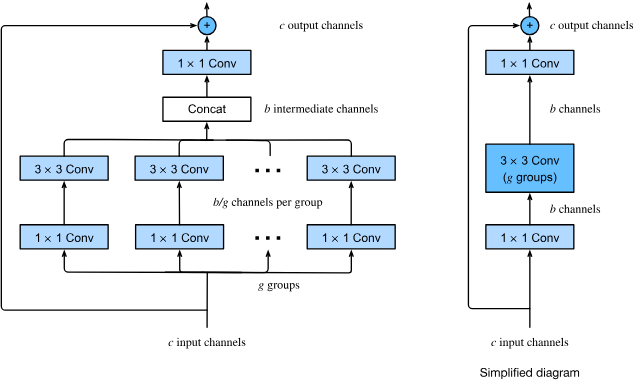

The ResNeXt block. The use of grouped convolution with $\mathit{g}$ groups is $\mathit{g}$ times faster than a dense convolution (recall block-diagonal matrix from Ch.7) . It is a bottleneck residual block when the number of intermediate channels $\mathit{b}$ is less than $\mathit{c}$.

* Grouped convolution both decreases the amount of computation that needs to be done and parameters needed to be stored by $g$
* Drawback is that no information is exchanged between each of the $g$ groups (corresponding to lack of off-diagonal interaction terms of block diagonal matrix)
    * Grouped Convolution of $3\times 3$ filter branches are sandwiched between two $1\times 1$ convolutions. The second $1\times 1$ filter has the dual purpose of changing the number of channels back, along with mixing information from different channels
    * Notice we pay a $\mathcal{O}(c \cdot b)$ cost for $1\times 1$ kernels. (recall $b$ is number of channels from 1 by 1 to 3 by 3, and again from 3 by 3 to 1 by 1). 
    * The residual branch for ResNeXt is added after the 2nd $1\times 1$ convolution (since same dimension)

In [ ]:
class ResNeXtBlock(nn.Module):  
    """
    The ResNeXt block.
    bot_mul: multiplier for number of channel that "main" conv filters see
    """
    def __init__(self, num_channels, groups, bot_mul, use_1x1conv=False,
                 strides=1):
        super().__init__()
        bot_channels = int(round(num_channels * bot_mul))

        # First 1x1 conv layer
        self.conv1 = nn.LazyConv2d(bot_channels, kernel_size=1, stride=1)
        self.bn1 = nn.LazyBatchNorm2d()

        # Main branches of block. Padding to preserve spatial dims
        self.conv2 = nn.LazyConv2d(bot_channels, kernel_size=3,
                                   stride=strides, padding=1,
                                   groups=bot_channels//groups)
        self.bn2 = nn.LazyBatchNorm2d()

        # 1x1 conv to restore channel dimension after conv2
        self.conv3 = nn.LazyConv2d(num_channels, kernel_size=1, stride=1)
        self.bn3 = nn.LazyBatchNorm2d()

        if use_1x1conv: # Residual connectin conv filter
            self.conv4 = nn.LazyConv2d(num_channels, kernel_size=1,
                                       stride=strides)
            self.bn4 = nn.LazyBatchNorm2d()
        else:
            self.conv4 = None

    def forward(self, X):
        Y = F.relu(self.bn1(self.conv1(X)))
        Y = F.relu(self.bn2(self.conv2(Y)))
        Y = self.bn3(self.conv3(Y))
        if self.conv4:
            X = self.bn4(self.conv4(X))
        return F.relu(Y + X)

In [ ]:
# Output shape same as input shap
blk = ResNeXtBlock(num_channels=32, groups=16, bot_mul=1, use_1x1conv=False, strides=1)
X = torch.randn(4, 32, 96, 96)
blk(X).shape, blk.conv2.weight.shape 

(torch.Size([4, 32, 96, 96]), torch.Size([32, 16, 3, 3]))

In [ ]:
# Changing bot_mul dosen't change output shape of block, only the internasl
blk = ResNeXtBlock(num_channels=32, groups=16, bot_mul=2, use_1x1conv=False, strides=1)
X = torch.randn(4, 32, 96, 96)
blk(X).shape, blk.conv2.weight.shape

(torch.Size([4, 32, 96, 96]), torch.Size([64, 16, 3, 3]))

### 8.6.6 Summary and Discussion
* Derive Residual block with nested function and identity mapping of blocks. Changed inductive bias of simple functions from $f(x)=0$ to $f(x)=x$
* Identity mapping allows information to flow back and forth faster and better, awhich helps training in some cases
* Combine with multi-branch idea of Inception blocks to get ResNeXt blocks

### 8.6.7 Exercises
1. What are the major differences between the Inception block in and the residual block? How do they compare in terms of computation, accuracy, and the classes of functions they can describe?
1. Refer to Table 1 in the ResNet paper He.Zhang.Ren.ea.2016 to implement different variants of the network. 
1. For deeper networks, ResNet introduces a "bottleneck" architecture to reduce model complexity. Try to implement it.
1. In subsequent versions of ResNet, the authors changed the "convolution, batch normalization, and activation" structure to the "batch normalization, activation, and convolution" structure. Make this improvement yourself. See Figure 1 in He.Zhang.Ren.ea.2016 for details.
1. Why can't we just increase the complexity of functions without bound, even if the function classes are nested?

Exercise #1
* Residual block is garunteed to contain the identity mapping transformation, the Inception block can still learn that, but it does not have the inductive bias that the residual block does in this regard
* The standard Inception block will be more compute heavy due to having much more conv layers
* Reasonable to believe that Inception block can be more complex than standard Residual block. For same reason, Inception block would contribute more to accuracy on its own. However, when building significantly deeper networks, Residual blocks would shine  

Exercise #2
* Implemented ResNet-50 below, based on description in Table 1 of 2016 ResNet paper
* Not trained, would take too long
* Also, since is ResNet50, bottleneck block is added here. Skipping Ex3 since alr included here. 

In [93]:
class ResidualBlock(nn.Module):
    """Bottleneck for ResNet-50/101/152, taken from Fig. 5 of the original paper.
    Incoming and outgoing dimensions are both 256. Paper said batch normalizations are
    applied after each conv and before activation layers. 
    """
    def __init__(self, chn1, chn2, chn3, downsample=False):
        super().__init__()
        if downsample:
            stride = 2
        else:
            stride = 1

        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=chn1, kernel_size=1), nn.LazyBatchNorm2d(), nn.ReLU(),
            nn.LazyConv2d(out_channels=chn2, kernel_size=3, padding=1, stride=stride), nn.LazyBatchNorm2d(), nn.ReLU(),
            nn.LazyConv2d(out_channels=chn3, kernel_size=1), nn.LazyBatchNorm2d(),
        )
        self.skip = nn.LazyConv2d(out_channels=chn3, kernel_size=1, stride=stride)

    def forward(self, X):
        """Skip connection is always changging output channel count w.r.t. input channel count"""
        return F.relu(self.net(X) + self.skip(X))



class MyResNet_50(d2l.Classifier):
    """My ResNet-50 implementation. num_classes=10 for FashionMNIST, although original
    was 1000 for ImageNet.
    
    architecture = (num_residuals, (chn1, chn2, chn3) )
    """
    def __init__(self, architecture, lr=0.05, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(self.section1())

        for i, chn_tuple in enumerate(architecture):
            self.net.add_module(f'b{i+2}', self.block(*chn_tuple, downsample=(i != 0)))

        self.net.add_module('last', nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
            nn.LazyLinear(num_classes)
        ))
        # self.net_apply(d2l.init_cnn)

    def section1(self):
        block1 = nn.Sequential(
            nn.LazyConv2d(out_channels=64, kernel_size=7, stride=2, padding=3),
            nn.LazyBatchNorm2d(), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        return block1

    
    def block(self, num_residuals, chn_tuple, downsample=False):
        """first_block needed since conv2 does not downsample, but conv3, 4, 5 do. Check Table1
        """
        blk = []
        for i in range(num_residuals):
            blk.append(ResidualBlock(*chn_tuple, downsample=(i == 0 and downsample)))
        return nn.Sequential(*blk)
    


class ResNet50(MyResNet_50):
    def __init__(self, lr=0.05, num_classes=10):
        super().__init__(
            architecture=(
                (3, (64, 64, 256)),
                (4, (128, 128, 512)),
                (6, (256, 256, 1024)),
                (3, (512, 512, 2048))
            ),
            lr=lr,
            num_classes=num_classes
        )


ResNet50().layer_summary((1, 1, 224, 224))

Sequential output shape:	 torch.Size([1, 64, 56, 56])
Sequential output shape:	 torch.Size([1, 256, 56, 56])
Sequential output shape:	 torch.Size([1, 512, 28, 28])
Sequential output shape:	 torch.Size([1, 1024, 14, 14])
Sequential output shape:	 torch.Size([1, 2048, 7, 7])
Sequential output shape:	 torch.Size([1, 10])


Validation accuracy for modelEx2: 87.98%


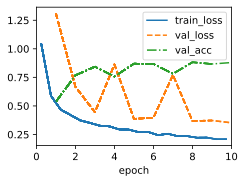

In [ ]:
# Training is a bit unstable and indicates overfitting. End result 
# val acc is p good at 87.98%
# Main goal was just to check if the model itself is trainable

class TestTrainResNet20(MyResNet_50):
    def __init__(self, lr=0.05, num_classes=10):
        super().__init__(
            architecture=(
                (2, (32, 32, 64)),
                (2, (64, 64, 125)),
                (2, (128, 128, 256)),
            ),
            lr=lr,
            num_classes=num_classes
        )


trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
modelEx2 = TestTrainResNet20(lr=0.05, num_classes=10)
modelEx2.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(modelEx2, data)

ex2_val_acc = evaluate_accuracy(modelEx2, data)
print(f"Validation accuracy for modelEx2: {ex2_val_acc*100:.2f}%")

Exercise #3
* Included in ResNet-50 implementation above in Ex2

Exercise #4
* Compare with the ResidualBlock implemented above for Ex2


In [ ]:
class ResidualBlock(nn.Module):
    """Bottleneck for ResNet-50/101/152, taken from Fig. 5 of the original paper.
    Incoming and outgoing dimensions are both 256. Paper said batch normalizations are
    applied after each conv and before activation layers. 
    """
    def __init__(self, chn1, chn2, chn3, downsample=False):
        super().__init__()
        if downsample:
            stride = 2
        else:
            stride = 1

        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=chn1, kernel_size=1), nn.ReLU(), nn.LazyBatchNorm2d(), 
            nn.LazyConv2d(out_channels=chn2, kernel_size=3, padding=1, stride=stride), nn.ReLU(), nn.LazyBatchNorm2d(),
            nn.LazyConv2d(out_channels=chn3, kernel_size=1), nn.LazyBatchNorm2d(),
        )
        self.skip = nn.LazyConv2d(out_channels=chn3, kernel_size=1, stride=stride)

    def forward(self, X):
        """Skip connection is always changging output channel count w.r.t. input channel count"""
        return F.relu(self.net(X) + self.skip(X))

Exercise #5
* If the complexity is increased without bound, then it is possible that the function (neural network) can start fitting to noise rather than picking up patterns/representations. This would happen if functions are continuously made more complex, regardless if they are nested or not

# 8.7. Densely Connected Networks (DenseNet)

* Take a look at Huang et.al 2017 paper later
* Main ieda is that each layer connects to all preceding layers and concatenates them to preserve/reference/reuse features from earlier layers

### 8.7.1 From ResNet to DenseNet

* Recall the Taylor expansion. About point $x = 0$ it can be written as:

$$f(x) = f(0) + x \cdot \left[f'(0) + x \cdot \left[\frac{f''(0)}{2!}  + x \cdot \left[\frac{f'''(0)}{3!}  + \cdots \right]\right]\right].$$

* Key point is that it decomposes a function into terms of increasingly higher order. 
* ResNet decomposes functions into a simple linear (identity term) and a more complex, nonlinear one (the residual mapping): 
$$f(\mathbf{x}) = \mathbf{x} + g(\mathbf{x}).$$

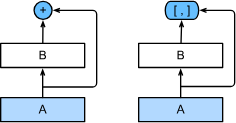 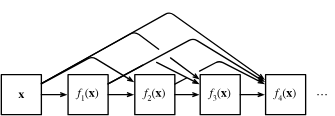

Left: Resnet. Right: DenseNet

Note, the $[,]$ means concatenate rather than add. Thus, we are performing a mapping form input $x$ to its values after applying increasingly compelx sequence of functions, which are combined into an MLP at the end to reduce the number of features again. 

$$\mathbf{x} \to \left[
\mathbf{x},
f_1(\mathbf{x}),
f_2\left(\left[\mathbf{x}, f_1\left(\mathbf{x}\right)\right]\right), f_3\left(\left[\mathbf{x}, f_1\left(\mathbf{x}\right), f_2\left(\left[\mathbf{x}, f_1\left(\mathbf{x}\right)\right]\right)\right]\right), \ldots\right]$$

Main Implementation Details:
* Instead of adding features, concatenates features/representations
* Dense Blocks: Define how inputs & outputs are concatenated
* Transistion Layers: Control number of channels s.t. it is not too large (since constantly referring to initial image + each representation can increase dimensions quickly)

### 8.7.2 Dense Blocks
* Convolution Block: Uses modified "batch norm, activation, convolution" structure from subsequent version of ResNet 
* Dense Block: Uses multiple convolution blcoks, each wit the same numebr of output channels. In forward method, we concatenate the input and output of each convolution block along the channel dimension

In [101]:
def conv_block(num_channels):
    conv_block = nn.Sequential(
        nn.LazyBatchNorm2d(), nn.ReLU(),
        nn.LazyConv2d(num_channels, kernel_size=3, padding=1)
        )
    return conv_block


class DenseBlock(nn.Module):
    def __init__(self, num_convs, num_channels):
        super(DenseBlock, self).__init__()
        layer = []
        for i in range(num_convs):
            layer.append(conv_block(num_channels))
        self.net = nn.Sequential(*layer)

    def forward(self, X):
        for blk in self.net:
            Y = blk(X)

            # Concatenate input and output of each block along channel dim
            X = torch.cat((X, Y), dim=1)
        return X

In [102]:
# Initial input of 3 channels, 2 blocks where each block itself produces 10 output channels
# Expect and see 3 + 2*10 = 23 output channels after this instance of DenseBlock
blk = DenseBlock(2, 10)
X = torch.randn(4, 3, 8, 8)
Y = blk(X)
Y.shape

torch.Size([4, 23, 8, 8])

### 8.7.3 Transition Layers

* Each DenseBlock increases the number of channels, which can lead to an excessively complex model 
* Transistion Layer ued to control/restrain complexity of the model by reducing the number of channels w/ $1\times 1$ convolutions. It also halves both the height and the width using an average pool (not max pool apparently) with a stride of 2

In [103]:
def transition_block(num_channels):
    return nn.Sequential(
        nn.LazyBatchNorm2d(), nn.ReLU(),
        nn.LazyConv2d(num_channels, kernel_size=1),
        nn.AvgPool2d(kernel_size=2, stride=2))

In [104]:
# Apply Transistion Block to previous DenseBlock output to reduce output channel count and spatial dimensions
blk = transition_block(10)
blk(Y).shape

torch.Size([4, 10, 4, 4])

### 8.7.4 DenseNet Model

* Has same single convolutional layer and max-pooling as ResNet
* 4 DenseBlocks, where we set 4 convolutional layers per block (consistent with ResNet-18 fo rnow)
* Set number of channels (i.e. growth rate) to 32, so 128 channels will be added for each DenseBlock
* Height & Width are halved, along with the number of channels
* Finish with Global Average Pooling and FC layer to produce final prediction

In [105]:
class DenseNet(d2l.Classifier):
    def __init__(self, num_channels=64, 
                 growth_rate=32, 
                 architecture=(4, 4, 4, 4),
                 lr=0.1, 
                 num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(self.b1())

        for i, num_convs in enumerate(architecture):
            self.net.add_module(f'dense_blk{i+1}', DenseBlock(num_convs, growth_rate))
            # The number of output channels in the previous dense block
            num_channels += num_convs * growth_rate

            # A transition layer that halves the number of channels is added
            # between the dense blocks
            if i != len(architecture) - 1:
                num_channels //= 2
                self.net.add_module(f'tran_blk{i+1}', transition_block(num_channels))
                
        self.net.add_module('last', nn.Sequential(
            nn.LazyBatchNorm2d(), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
            nn.LazyLinear(num_classes)))
        
        self.net.apply(d2l.init_cnn)

    def b1(self):
        block1 = nn.Sequential(
            nn.LazyConv2d(out_channels=64, kernel_size=7, stride=2, padding=3),
            nn.LazyBatchNorm2d(), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
        return block1
    
DenseNet().layer_summary((1, 1, 96, 96))

Sequential output shape:	 torch.Size([1, 64, 24, 24])
DenseBlock output shape:	 torch.Size([1, 192, 24, 24])
Sequential output shape:	 torch.Size([1, 96, 12, 12])
DenseBlock output shape:	 torch.Size([1, 224, 12, 12])
Sequential output shape:	 torch.Size([1, 112, 6, 6])
DenseBlock output shape:	 torch.Size([1, 240, 6, 6])
Sequential output shape:	 torch.Size([1, 120, 3, 3])
DenseBlock output shape:	 torch.Size([1, 248, 3, 3])
Sequential output shape:	 torch.Size([1, 10])


### 8.7.5 Training

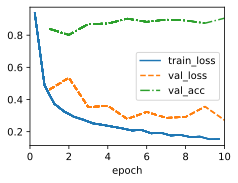

In [117]:
model = DenseNet(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96)) # Note size of initial input
trainer.fit(model, data)

In [118]:
final_val_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * final_val_acc:.2f}%")

Final validation accuracy: 90.53%


### 8.7.6 Summary and Discussion

* Concatenate all inputs/representations so far at each block - "DenseBlock"
* Use transistion blocks to downsample channel dimensions - otherwise would keep growing

### 8.7.7 Exercises
1. Why do we use average pooling rather than max-pooling in the transition layer?
1. One of the advantages mentioned in the DenseNet paper is that its model parameters are smaller than those of ResNet. Why is this the case?
1. One problem for which DenseNet has been criticized is its high memory consumption.
    1. Is this really the case? Try to change the input shape to $224\times 224$ to compare the actual GPU memory consumption empirically.
    1. Can you think of an alternative means of reducing the memory consumption? How would you need to change the framework?
1. Implement the various DenseNet versions presented in Table 1 of the DenseNet paper Huang.Liu.Van-Der-Maaten.ea.2017.
1. Design an MLP-based model by applying the DenseNet idea. Apply it to the housing price prediction task in Kaggle House price section.

Exercise #1
* DenseNet uses average pooling rather than max-pooling to take advantage of informatino mixing from all previous layers instead of selecting the highest/most-dominant features/representations. 
* MaxPool may end up discarding some information that is still useful in context of DenseNets

Exercise #2
* Probably because it is not as deep as ResNets
* Or something to do with limited growth rates of DenseNets. ResNets double output channels each Residual Grouping

Exercise #3
* Skip. IDT its a good use of my time. Need to move onto other things.

Exercise #4
* Skip. IDT its a good use of my time. Need to move onto other things.

Exercise #5
* Skip. IDT its a good use of my time. Need to move onto other things.

# 8.8. Designing Convolution Network Architectures

Just Reread this section when I need to: https://d2l.ai/chapter_convolutional-modern/cnn-design.html

### 8.8.1 The AnyNet Design Space

### 8.8.2 Distributions and Parameters of Design Spaces

### 8.8.3 RegNet

### 8.8.4 Training

### 8.8.5 Discussion

### 8.8.6 Exercises
1. Increase the number of stages to four. Can you design a deeper RegNetX that performs better?
1. De-ResNeXt-ify RegNets by replacing the ResNeXt block with the ResNet block. How does your new model perform?
1. Implement multiple instances of a "VioNet" family by *violating* the design principles of RegNetX. How do they perform? Which of ($d_i$, $c_i$, $g_i$, $b_i$) is the most important factor?
1. Your goal is to design the "perfect" MLP. Can you use the design principles introduced above to find good architectures? Is it possible to extrapolate from small to large networks?


Skip all exercises. I want to get to Chapter 14. Looks more fun/important